<a href="https://colab.research.google.com/github/tech-picnic/20201112_flask_with_iot_sensor/blob/main/9_%EA%B8%B0%EC%88%A0%EC%A0%81_%EC%A7%80%ED%91%9C_%EB%B0%B1%ED%85%8C%EC%8A%A4%ED%8A%B8_%EC%B0%A8%ED%8A%B8_%ED%8A%B8%EB%A0%88%EC%9D%B4%EB%94%A9_%EC%8B%9C%EB%AE%AC%EB%A0%88%EC%9D%B4%EC%85%98_%ED%95%98%EA%B8%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 기술적 지표 백테스트 - 차트 트레이딩 시뮬레이션 하기

- 손절매가 필수적인 통계적 근거: 모든 주식에 대한 보유 기간별 수익률 검증
- 이평선을 이용한 투자전략1: 이평선 위에서 매수할때, 아래에서 매수할 때
- 이평선을 이용한 투자전략2: 정배열에서 매수할때, 역배열에서 매수할 때
- 이평선을 이용한 투자전략3: 골든크로스 발생 시점에 매수할 때
- 볼린저밴드를 이용한 투자전략1: 볼린저밴드의 폭 너비에 따라 매수할 때
- 볼린저밴드를 이용한 투자전략2: 상한선 위에서 매수할 때, 하한선 아래에서 매수할 때

In [1]:
# COLAB 환경을 위한 나눔고딕 한글폰트 설치  --> 진행 후,  런타임 > 런타임 다시 시작을 해 주세요. 다시 시작 후에는 이 부분 실행 X
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 0 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 2s (6,056 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and 

In [2]:
# 데이터 다운로드
!wget "https://gist.githubusercontent.com/solaris33/19a66481d20b9a4341be9cf624c74c14/raw/93429bb192c6a24b46a336f0877d51cfc2ca853f/stock.adj_close.csv" -O "stock.adj_close.csv"
!wget "https://gist.githubusercontent.com/solaris33/51380a44d820ef8441557624e9bc8e01/raw/00b38b56450972bd79dc3143784153b3b9e6db3f/stock.mc.csv" -O "stock.mc.csv"
!wget "https://gist.githubusercontent.com/solaris33/5efcf103311b011fc5f4ffc589bf9408/raw/29ce53d1949684794f58af91cc749ce120cd864e/stock.sales_ttm.csv" -O "stock.sales_ttm.csv"
!wget "https://gist.githubusercontent.com/solaris33/3a12f79ae814f2198dbe263f09ff4365/raw/df5ba51fac00e2a3f3ebfb7d6ef99f7147c425ef/stock.op_ttm.csv" -O "stock.op_ttm.csv"
!wget "https://gist.githubusercontent.com/solaris33/62506befa4255988910ea8bb37be7ee5/raw/0996b4118398cc4a4a51047e49af971718d89bb0/stock.ni_ttm.csv" -O "stock.ni_ttm.csv"
!wget "https://gist.githubusercontent.com/solaris33/5f6adeb82ed9055e5bb8636ae772afec/raw/fd33f6fa5cf7e40c6975688656b5dfdfe8704da5/stock.asset_cur.csv" -O "stock.asset_cur.csv"
!wget "https://gist.githubusercontent.com/solaris33/f0c4c969f2b67ce01d9f5607be28cf71/raw/e810b51b910218ee9b97e54687abe1261c4968d5/stock.liab.csv" -O "stock.liab.csv"
!wget "https://gist.githubusercontent.com/solaris33/11bed00db025a74d4536d5e9947d3131/raw/672ca99b8b17ee11f748524e7a8946f821f3a0ff/stock.eq.csv" -O "stock.eq.csv"
!wget "https://gist.githubusercontent.com/solaris33/22803c36480ed2ff23f441318db8b07b/raw/82e8db933246530a11f1db0aea066f0dc1b929ed/stockinfo.itemname.csv" -O "stockinfo.itemname.csv"
!wget "https://gist.githubusercontent.com/solaris33/e55f2b24086f8c73d8c9aca4f8043b45/raw/0a11dbc036b46ce567c6a399d2a18a0e7dbe3e1f/stockinfo.sector.csv" -O "stockinfo.sector.csv"

--2026-11-12 02:08:06--  https://gist.githubusercontent.com/solaris33/19a66481d20b9a4341be9cf624c74c14/raw/93429bb192c6a24b46a336f0877d51cfc2ca853f/stock.adj_close.csv
Resolving gist.githubusercontent.com (gist.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.109.133, ...
Connecting to gist.githubusercontent.com (gist.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14555936 (14M) [text/plain]
Saving to: ‘stock.adj_close.csv’

stock.adj_close.csv 100%[===================>]  13.88M  --.-KB/s    in 0.1s    

2026-11-12 02:08:07 (139 MB/s) - ‘stock.adj_close.csv’ saved [14555936/14555936]

--2026-11-12 02:08:07--  https://gist.githubusercontent.com/solaris33/51380a44d820ef8441557624e9bc8e01/raw/00b38b56450972bd79dc3143784153b3b9e6db3f/stock.mc.csv
Resolving gist.githubusercontent.com (gist.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.109.133, ...
Connecting to gist.githubusercontent.c

## 라이브러리 임포트

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
sns.set()

# 한글 폰트 설정 (Colab 나눔바른고딕, 윈도우 Malgun Gothic,  리눅스&Mac AppltGothic)
plt.rcParams['font.family'] = ['NanumBarunGothic', 'Malgun Gothic', 'AppleGothic']
plt.rcParams['axes.unicode_minus'] = False    # 문자 - (마이너스) 정상 출력을 위한 코드
%matplotlib inline

# pandas 출력 소숫점 자리 수정하기 (필요 시)
pd.set_option('display.float_format', '{:,.4f}'.format)
# 기본값은 None
# pd.options.display.float_format = None

## 데이터 불러오기

#### 일자별 주식 데이터 불러오기 (dict 및 for문 사용)

In [19]:
d = {}

# For문 이용하여 읽기- 주가, 시가총액, 매출액, 영업익, 순이익, 부채, 유동자산, 자본
for data_name in ['adj_close', 'mc', 'sales_ttm', 'op_ttm', 'ni_ttm', 'liab', 'asset_cur', 'eq']:
    print(f"read csv {data_name} ...")
    d[data_name] = pd.read_csv(f"./stock.{data_name}.csv", index_col=0, encoding='cp949', parse_dates=True)

    print(f"done!  {d[data_name].shape}")

read csv adj_close ...


/tmp/ipykernel_598/318251874.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d[data_name] = pd.read_csv(f"./stock.{data_name}.csv", index_col=0, encoding='cp949', parse_dates=True)


done!  (2396, 883)
read csv mc ...


/tmp/ipykernel_598/318251874.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d[data_name] = pd.read_csv(f"./stock.{data_name}.csv", index_col=0, encoding='cp949', parse_dates=True)


done!  (2396, 883)
read csv sales_ttm ...


/tmp/ipykernel_598/318251874.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d[data_name] = pd.read_csv(f"./stock.{data_name}.csv", index_col=0, encoding='cp949', parse_dates=True)


... (6 outputs left out)

done!  (2396, 883)
read csv asset_cur ...


/tmp/ipykernel_598/318251874.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d[data_name] = pd.read_csv(f"./stock.{data_name}.csv", index_col=0, encoding='cp949', parse_dates=True)


done!  (2396, 883)
read csv eq ...
done!  (2396, 883)


/tmp/ipykernel_598/318251874.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d[data_name] = pd.read_csv(f"./stock.{data_name}.csv", index_col=0, encoding='cp949', parse_dates=True)


In [140]:
d = {}

# For문 이용하여 읽기- 주가, 시가총액, 매출액, 영업익, 순이익, 부채, 유동자산, 자본
for data_name in ['adj_close', 'mc', 'sales_ttm', 'op_ttm', 'ni_ttm', 'liab', 'asset_cur', 'eq']:
    # print(f"read csv {data_name} ...")
    d[data_name] = pd.read_csv(f"./stock.{data_name}.csv", index_col=0, encoding='cp949')

    # 인덱스가 아닌 '컬럼(열)'이 날짜이므로 컬럼을 datetime으로 변환합니다.
    d[data_name].columns = pd.to_datetime(d[data_name].columns, format='%Y-%m-%d')
    # print(f"done!  {d[data_name].shape}")

In [27]:
mc = d['mc']
adj_close = d['adj_close']

In [28]:
adj_close

,2018-01-02,2018-01-03,2018-01-04,2018-01-05,2018-01-08,2018-01-09,2018-01-10,2018-01-11,2018-01-12,2018-01-15,...,2021-07-19,2021-07-20,2021-07-21,2021-07-22,2021-07-23,2021-07-26,2021-07-27,2021-07-28,2021-07-29,2021-07-30
Symbol,,,,,,,,,,,,,,,,,,,,,
A000020,"9,870.0000","10,000.0000","9,750.0000","9,910.0000","9,950.0000","9,770.0000","9,840.0000","10,300.0000","10,250.0000","10,350.0000",...,"15,100.0000","14,900.0000","14,800.0000","14,750.0000","14,600.0000","14,400.0000","14,400.0000","14,450.0000","14,600.0000","14,650.0000"
A000030,"15,900.0000","15,800.0000","15,650.0000","15,750.0000","16,300.0000","16,650.0000","16,800.0000","16,950.0000","17,150.0000","16,850.0000",...,"14,800.0000","14,800.0000","14,800.0000","14,800.0000","14,800.0000","14,800.0000","14,800.0000","14,800.0000","14,800.0000","14,800.0000"
A000040,"1,985.0000","1,985.0000","1,985.0000","1,985.0000","1,985.0000","1,985.0000","1,985.0000","1,985.0000","1,985.0000","2,627.0000",...,"1,295.0000","1,300.0000","1,280.0000","1,295.0000","1,275.0000","1,240.0000","1,250.0000","1,235.0000","1,255.0000","1,235.0000"
A000050,"13,850.0000","13,750.0000","13,750.0000","13,550.0000","13,450.0000","13,600.0000","13,600.0000","13,750.0000","13,900.0000","14,100.0000",...,"13,500.0000","13,300.0000","13,200.0000","13,400.0000","13,450.0000","13,300.0000","13,350.0000","13,200.0000","13,450.0000","13,600.0000"
A000060,"23,350.0000","23,350.0000","22,700.0000","23,250.0000","23,000.0000","23,150.0000","22,850.0000","23,600.0000","23,650.0000","24,450.0000",...,"21,850.0000","21,900.0000","22,450.0000","22,550.0000","22,900.0000","22,800.0000","23,350.0000","23,850.0000","24,950.0000","25,500.0000"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
A950180,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"22,150.0000","21,550.0000","21,750.0000","21,850.0000","22,350.0000","21,300.0000","21,000.0000","20,750.0000","21,150.0000","21,250.0000"
A950190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"23,000.0000","23,100.0000","22,900.0000","22,900.0000","23,150.0000","23,050.0000","22,250.0000","22,250.0000","22,500.0000","22,300.0000"
A950200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"13,650.0000","13,400.0000","13,100.0000","13,450.0000","13,250.0000","13,000.0000","13,050.0000","13,000.0000","13,150.0000","13,150.0000"


## Utils

In [29]:
# midxs가 True인 인덱스에서 보유일 (hold_day)별로 수익률을 구해주는 함수

def get_all_return_df_by(d, midxs, hold_day_li=[1,2,3,5,10,20,40,60,120]):
    return pd.concat([pd.Series(d[f'close_return_{hold_day}d'].stack(dropna=False).loc[midxs], name=f'{hold_day}일 보유') for hold_day in hold_day_li], axis=1)

In [42]:
def describe_and_aggperf(ret_midxdf):
    _desc_df = ret_midxdf.describe()

    eachcols_nrecords = ret_midxdf.notna().sum(axis=0)
    _win_df = ret_midxdf.map(lambda e: e if e >= 0 else np.nan)
    _loss_df = ret_midxdf.map(lambda e: e if e < 0 else np.nan)

    # pd.concat을 사용하여 기존 DataFrame에 새로운 Series를 행(axis=0)으로 추가합니다.
    new_rows = pd.DataFrame([
        pd.Series(((ret_midxdf >= 0).sum(axis=0) / eachcols_nrecords), name='win_rate'),
        pd.Series(_win_df.count(axis=0), name='win_count'),
        pd.Series(_win_df.mean(axis=0), name='win_return_mean'),
        pd.Series(_win_df.median(axis=0), name='win_return_median'),
        pd.Series(((ret_midxdf < 0).sum(axis=0) / eachcols_nrecords), name='loss_rate'),
        pd.Series(_loss_df.count(axis=0), name='loss_count'),
        pd.Series(_loss_df.mean(axis=0), name='loss_return_mean'),
        pd.Series(_loss_df.median(axis=0), name='loss_return_median')
    ])

    _desc_df = pd.concat([_desc_df, new_rows], axis=0)

    return _desc_df

In [38]:
# 퀀트 분석 결과에 대해 boxplot 차트를 그려주는 함수

def draw_meanmed_boxplot(_df, _title=None, _figsize=(18,9)):
    _ax = _df.boxplot(figsize=_figsize, showfliers=False, showmeans=True);
    if _title:
        _ax.set_title(_title, fontweight='bold');

    legend_elements = [plt.Line2D([0], [0], marker='^', color='None', label='평균 값', markerfacecolor='g', markeredgecolor='None', markersize=15),
                       plt.Line2D([0], [0], color='gray', lw=2, label='중앙 값')]
    _ax.legend(handles=legend_elements, loc='upper left');

    _ytmin, _ytmax = round(_ax.get_yticks()[0],1), round(_ax.get_yticks()[-1],1)
    _gap = 0.1 if (_ytmax - _ytmin) > 1.6 else 0.05

    _yticks = np.arange(_ytmin, _ytmax, _gap)
    _yticklabels = list(map(lambda e: int(e),np.arange(100*_ytmin, 100*_ytmax, 100*_gap)))

    _ax.set_yticks(_yticks)
    _ax.set_yticklabels(_yticklabels)
    _ax.axhline(0, linewidth=1)

    return _ax

## 손절매가 필수적인 통계적 근거

In [39]:
# 퀀트 분석 결과를 저장할 딕셔너리
exp = {}

In [40]:
exp

{}

In [41]:
_sr_li = list()
for hold_day in [1, 2, 3, 5, 10, 20, 40, 60, 120, 240]:

    _df = adj_close.iloc[:, ::hold_day]
    _prev = _df.shift(1, axis=1).replace(0, np.nan)
    _ret = ((_df / _prev) - 1).stack(dropna=False)

    _sr_li.append((pd.Series(_ret.values, name=f'{hold_day}일_보유')))

/tmp/ipykernel_598/1207546009.py:6: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  _ret = ((_df / _prev) - 1).stack(dropna=False)
/tmp/ipykernel_598/1207546009.py:6: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  _ret = ((_df / _prev) - 1).stack(dropna=False)
/tmp/ipykernel_598/1207546009.py:6: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  _ret = ((_df / _prev) - 

In [14]:
exp_df = pd.DataFrame(_sr_li).T

In [15]:
exp_df

,1일_보유,2일_보유,3일_보유,5일_보유,10일_보유,20일_보유,40일_보유,60일_보유,120일_보유,240일_보유
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.0132,-0.0122,0.0041,-0.0101,0.0182,0.0942,0.1702,0.2411,0.0334,-0.1054
2,-0.0250,0.0205,-0.0071,0.0287,0.0746,0.0694,0.0087,-0.1673,-0.1343,-0.0929
3,0.0164,-0.0111,0.0518,0.0448,-0.0324,0.0606,-0.1245,0.1029,0.1189,1.3720
4,0.0040,0.0417,-0.0242,0.0286,0.1053,-0.0490,0.1225,-0.2151,-0.1893,NaN
...,...,...,...,...,...,...,...,...,...,...
2115663,0.0190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2115664,-0.0280,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2115665,-0.0048,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2115666,-0.0048,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
exp_df.describe()

,1일_보유,2일_보유,3일_보유,5일_보유,10일_보유,20일_보유,40일_보유,60일_보유,120일_보유,240일_보유
count,"1,951,110.0000","975,459.0000","650,249.0000","389,142.0000","194,479.0000","97,143.0000","48,487.0000","30,677.0000","15,255.0000","6,420.0000"
mean,0.0007,0.0015,0.0024,0.0042,0.0080,0.0167,0.0310,0.0501,0.0861,0.1010
std,0.0353,0.0505,0.0636,0.0856,0.1192,0.1754,0.2505,0.3323,0.4660,0.7459
min,-0.9732,-0.9732,-0.9753,-0.9932,-0.9932,-0.9932,-0.9932,-0.9932,-0.9932,-0.9935
25%,-0.0132,-0.0195,-0.0238,-0.0316,-0.0443,-0.0614,-0.0871,-0.1170,-0.1527,-0.2118
50%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0241
75%,0.0115,0.0175,0.0220,0.0306,0.0461,0.0735,0.1047,0.1408,0.1990,0.2035
max,1.9080,1.9080,1.9080,2.7019,3.3519,4.2944,5.5246,7.6229,8.5861,26.1223


In [43]:
describe_and_aggperf(exp_df)

,1일_보유,2일_보유,3일_보유,5일_보유,10일_보유,20일_보유,40일_보유,60일_보유,120일_보유,240일_보유
count,"1,951,110.0000","975,459.0000","650,249.0000","389,142.0000","194,479.0000","97,143.0000","48,487.0000","30,677.0000","15,255.0000","6,420.0000"
mean,0.0007,0.0015,0.0024,0.0042,0.0080,0.0167,0.0310,0.0501,0.0861,0.1010
std,0.0353,0.0505,0.0636,0.0856,0.1192,0.1754,0.2505,0.3323,0.4660,0.7459
min,-0.9732,-0.9732,-0.9753,-0.9932,-0.9932,-0.9932,-0.9932,-0.9932,-0.9932,-0.9935
25%,-0.0132,-0.0195,-0.0238,-0.0316,-0.0443,-0.0614,-0.0871,-0.1170,-0.1527,-0.2118
50%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0241
75%,0.0115,0.0175,0.0220,0.0306,0.0461,0.0735,0.1047,0.1408,0.1990,0.2035
max,1.9080,1.9080,1.9080,2.7019,3.3519,4.2944,5.5246,7.6229,8.5861,26.1223
win_rate,0.5449,0.5271,0.5249,0.5265,0.5318,0.5377,0.5321,0.5226,0.5136,0.4676
win_count,"1,063,078.0000","514,128.0000","341,347.0000","204,892.0000","103,417.0000","52,231.0000","25,800.0000","16,033.0000","7,835.0000","3,002.0000"


In [47]:
!sudo apt-get install -y fonts-nanum

# 2. Matplotlib의 폰트 캐시 업데이트를 위해 관련 디렉토리 정리
!rm -rf ~/.cache/matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 설치된 나눔바른고딕 폰트 경로 지정
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
font_prop = fm.FontProperties(fname=font_path)

# 전역 폰트 설정 변경
plt.rcParams['font.family'] = 'NanumBarunGothic'
# 마이너스(-) 기호 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


In [54]:
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

# 새로 설치된 나눔바른고딕 폰트를 시스템에 추가합니다.
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')

# Matplotlib의 내부 폰트 캐시 목록을 동기화하여 완전히 갱신합니다.
fm._load_fontmanager(try_read_cache=False)

# 전역 폰트 설정을 NanumBarunGothic으로 고정하고, 마이너스 기호 깨짐을 방지합니다.
plt.rcParams['font.family'] = 'NanumBarunGothic'
plt.rcParams['axes.unicode_minus'] = False

# 설정이 정상적으로 변경되었는지 확인합니다.
print("설정된 폰트:", plt.rcParams['font.family'])

설정된 폰트: ['NanumBarunGothic']


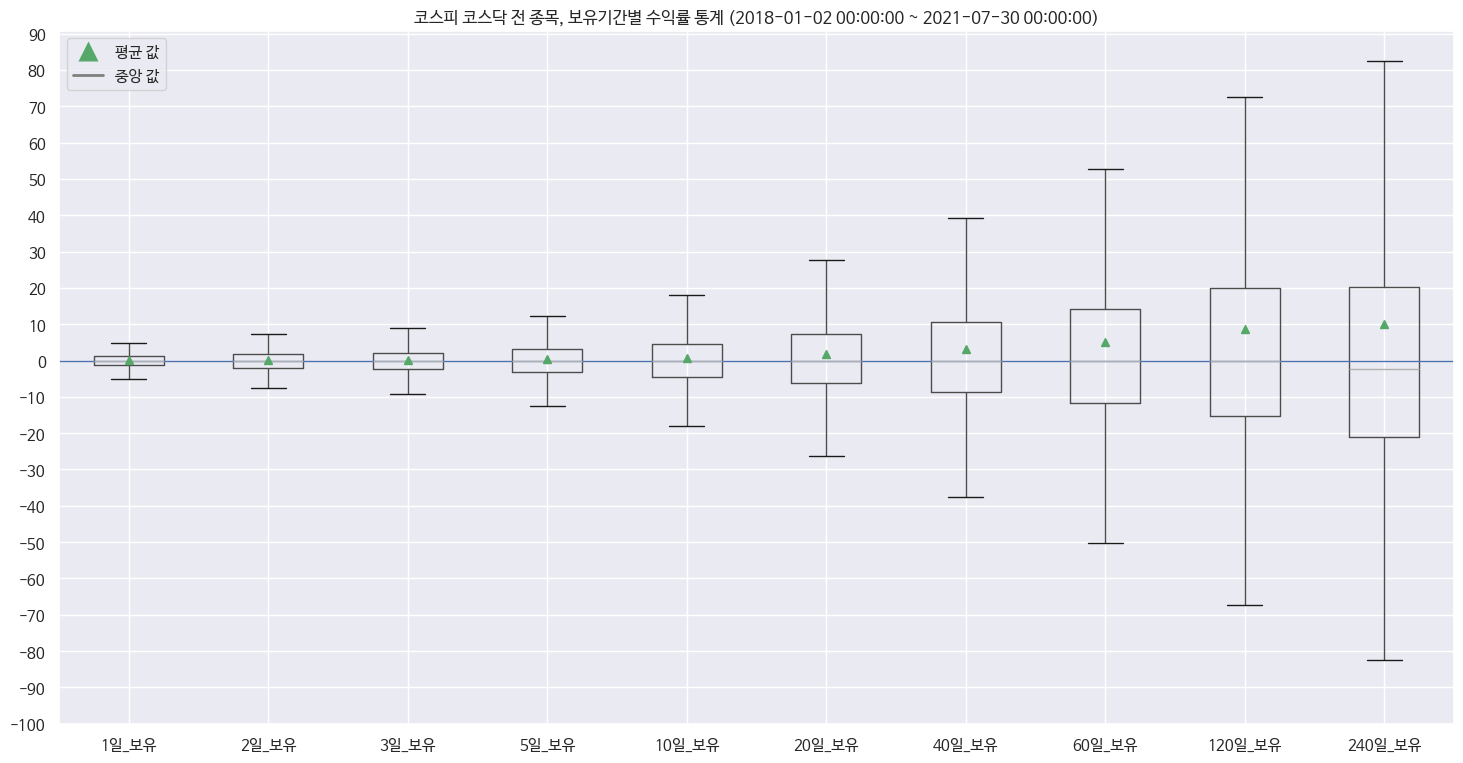

In [51]:
draw_meanmed_boxplot(exp_df, f'코스피 코스닥 전 종목, 보유기간별 수익률 통계 ({adj_close.columns[0]} ~ {adj_close.columns[-1]})');

## 이평선을 이용한 투자전략1: 이평선 위에서 매수할때, 아래에서 매수할 때

In [52]:
# 실험할 이평선 N일
sma_winli = [5, 10, 20, 40, 60, 120]

In [53]:
for win in sma_winli:
    d[f'adj_close_sma{win}d'] = adj_close.rolling(win, axis=1, min_periods=win//2).mean()

/tmp/ipykernel_598/2229182032.py:2: FutureWarning: Support for axis=1 in DataFrame.rolling is deprecated and will be removed in a future version. Use obj.T.rolling(...) instead
  d[f'adj_close_sma{win}d'] = adj_close.rolling(win, axis=1, min_periods=win//2).mean()
/tmp/ipykernel_598/2229182032.py:2: FutureWarning: Support for axis=1 in DataFrame.rolling is deprecated and will be removed in a future version. Use obj.T.rolling(...) instead
  d[f'adj_close_sma{win}d'] = adj_close.rolling(win, axis=1, min_periods=win//2).mean()
/tmp/ipykernel_598/2229182032.py:2: FutureWarning: Support for axis=1 in DataFrame.rolling is deprecated and will be removed in a future version. Use obj.T.rolling(...) instead
  d[f'adj_close_sma{win}d'] = adj_close.rolling(win, axis=1, min_periods=win//2).mean()
/tmp/ipykernel_598/2229182032.py:2: FutureWarning: Support for axis=1 in DataFrame.rolling is deprecated and will be removed in a future version. Use obj.T.rolling(...) instead
  d[f'adj_close_sma{win}d'] 

In [56]:
print('--- DataFrame 기본 정보 ---')
print(adj_close.info())

print('\n--- 결측치(NaN) 요약 ---')
total_elements = adj_close.size
null_elements = adj_close.isnull().sum().sum()
print(f'전체 데이터 개수: {total_elements:,}')
print(f'결측치 개수: {null_elements:,} ({null_elements/total_elements*100:.2f}%)')

# 종목(행)별, 일자(열)별 결측치 비율 확인
null_by_symbol = adj_close.isnull().mean(axis=1)
null_by_date = adj_close.isnull().mean(axis=0)

print('\n--- 종목별 결측치 비율 분포 (상위 5개) ---')
display(null_by_symbol.sort_values(ascending=False).head())

print('\n--- 일자별 결측치 비율 분포 (상위 5개) ---')
display(null_by_date.sort_values(ascending=False).head())

--- DataFrame 기본 정보 ---
<class 'pandas.core.frame.DataFrame'>
Index: 2396 entries, A000020 to A950220
Columns: 883 entries, 2018-01-02 to 2021-07-30
dtypes: float64(883)
memory usage: 16.2+ MB
None

--- 결측치(NaN) 요약 ---
전체 데이터 개수: 2,115,668
결측치 개수: 162,162 (7.66%)

--- 종목별 결측치 비율 분포 (상위 5개) ---


,0
Symbol,
A377030,0.9955
A365270,0.9921
A137310,0.9875
A352910,0.9841
A050320,0.9830



--- 일자별 결측치 비율 분포 (상위 5개) ---


,0
2018-01-02,0.1498
2018-01-03,0.1498
2018-01-04,0.1498
2018-01-05,0.1498
2018-01-08,0.1490


In [57]:
d['adj_close'].pct_change(periods=hold_day, axis=1, fill_method=None).shift(-hold_day, axis=1)

/tmp/ipykernel_598/165567763.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['adj_close'].pct_change(periods=hold_day, axis=1, fill_method=None).shift(-hold_day, axis=1)
/tmp/ipykernel_598/165567763.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['adj_close'].pct_change(periods=hold_day, axis=1, fill_method=None).shift(-hold_day, axis=1)
/tmp/ipykernel_598/165567763.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  

,2018-01-02,2018-01-03,2018-01-04,2018-01-05,2018-01-08,2018-01-09,2018-01-10,2018-01-11,2018-01-12,2018-01-15,...,2021-07-19,2021-07-20,2021-07-21,2021-07-22,2021-07-23,2021-07-26,2021-07-27,2021-07-28,2021-07-29,2021-07-30
Symbol,,,,,,,,,,,,,,,,,,,,,
A000020,-0.1054,-0.1270,-0.0728,-0.0817,-0.0613,-0.0614,-0.0315,-0.0748,-0.0712,-0.0870,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A000030,0.0283,0.0222,0.0032,-0.0095,-0.0552,-0.0601,-0.0833,-0.1416,-0.1370,-0.1217,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A000040,0.0388,0.0388,0.0227,0.0227,0.0227,0.0287,0.0287,0.0307,0.0368,-0.2086,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A000050,-0.1986,-0.2109,-0.2073,-0.2030,-0.1859,-0.1801,-0.1912,-0.1927,-0.2086,-0.1986,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A000060,-0.0707,-0.0600,-0.0507,-0.0602,-0.0717,-0.0972,-0.0503,-0.0678,-0.0507,-0.0961,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
A950180,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A950190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A950200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


```markdown
### 💡 DataFrame Fragmentation 경고 해결 및 최적화

여러 열을 반복문 안에서 개별적으로 추가할 때 메모리 파편화를 방지하기 위해 계산된 열들을 모아 한 번에 생성하거나 복사본을 만들어 최적화합니다.
```

In [59]:
# 1. 각 수익률 데이터프레임을 생성하여 딕셔너리에 모읍니다.
new_dfs = {}
for hold_day in [1, 2, 3, 5, 10, 20, 40, 60, 120]:
    # pct_change 계산 후 shift 적용
    ret_df = d['adj_close'].pct_change(periods=hold_day, axis=1, fill_method=None).shift(-hold_day, axis=1)
    new_dfs[f'close_return_{hold_day}d'] = ret_df

# 2. pd.concat을 사용해 여러 DataFrame을 한 번에 병합하여 메모리 파편화를 원천적으로 방지합니다.
# 기존 d 딕셔너리의 키 값으로 복사본(.copy())을 저장하여 확실하게 De-fragment를 진행합니다.
for key, df in new_dfs.items():
    d[key] = df.copy()

print("De-fragmentation 및 ValueError 해결 완료! 모든 수익률 데이터가 안정적으로 저장되었습니다.")

/tmp/ipykernel_598/2282078295.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ret_df = d['adj_close'].pct_change(periods=hold_day, axis=1, fill_method=None).shift(-hold_day, axis=1)
/tmp/ipykernel_598/2282078295.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ret_df = d['adj_close'].pct_change(periods=hold_day, axis=1, fill_method=None).shift(-hold_day, axis=1)
/tmp/ipykernel_598/2282078295.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which ha

De-fragmentation 및 ValueError 해결 완료! 모든 수익률 데이터가 안정적으로 저장되었습니다.


In [60]:
for hold_day in [1,2,3,5,10,20,40,60,120]:
    d[f'close_return_{hold_day}d'] = d['adj_close'].pct_change(periods=hold_day, axis=1, fill_method=None).shift(-hold_day, axis=1)
    print(f'close_return_{hold_day}d', d[f'close_return_{hold_day}d'].shape)

close_return_1d (2396, 883)
close_return_2d (2396, 883)
close_return_3d (2396, 883)
close_return_5d (2396, 883)
close_return_10d (2396, 883)
close_return_20d (2396, 883)
close_return_40d (2396, 883)
close_return_60d (2396, 883)
close_return_120d (2396, 883)


/tmp/ipykernel_598/2296082374.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d[f'close_return_{hold_day}d'] = d['adj_close'].pct_change(periods=hold_day, axis=1, fill_method=None).shift(-hold_day, axis=1)
/tmp/ipykernel_598/2296082374.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d[f'close_return_{hold_day}d'] = d['adj_close'].pct_change(periods=hold_day, axis=1, fill_method=None).shift(-hold_day, axis=1)
/tmp/ipykernel_598/2296082374.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the resul

In [62]:
adj_close

,2018-01-02,2018-01-03,2018-01-04,2018-01-05,2018-01-08,2018-01-09,2018-01-10,2018-01-11,2018-01-12,2018-01-15,...,2021-07-19,2021-07-20,2021-07-21,2021-07-22,2021-07-23,2021-07-26,2021-07-27,2021-07-28,2021-07-29,2021-07-30
Symbol,,,,,,,,,,,,,,,,,,,,,
A000020,"9,870.0000","10,000.0000","9,750.0000","9,910.0000","9,950.0000","9,770.0000","9,840.0000","10,300.0000","10,250.0000","10,350.0000",...,"15,100.0000","14,900.0000","14,800.0000","14,750.0000","14,600.0000","14,400.0000","14,400.0000","14,450.0000","14,600.0000","14,650.0000"
A000030,"15,900.0000","15,800.0000","15,650.0000","15,750.0000","16,300.0000","16,650.0000","16,800.0000","16,950.0000","17,150.0000","16,850.0000",...,"14,800.0000","14,800.0000","14,800.0000","14,800.0000","14,800.0000","14,800.0000","14,800.0000","14,800.0000","14,800.0000","14,800.0000"
A000040,"1,985.0000","1,985.0000","1,985.0000","1,985.0000","1,985.0000","1,985.0000","1,985.0000","1,985.0000","1,985.0000","2,627.0000",...,"1,295.0000","1,300.0000","1,280.0000","1,295.0000","1,275.0000","1,240.0000","1,250.0000","1,235.0000","1,255.0000","1,235.0000"
A000050,"13,850.0000","13,750.0000","13,750.0000","13,550.0000","13,450.0000","13,600.0000","13,600.0000","13,750.0000","13,900.0000","14,100.0000",...,"13,500.0000","13,300.0000","13,200.0000","13,400.0000","13,450.0000","13,300.0000","13,350.0000","13,200.0000","13,450.0000","13,600.0000"
A000060,"23,350.0000","23,350.0000","22,700.0000","23,250.0000","23,000.0000","23,150.0000","22,850.0000","23,600.0000","23,650.0000","24,450.0000",...,"21,850.0000","21,900.0000","22,450.0000","22,550.0000","22,900.0000","22,800.0000","23,350.0000","23,850.0000","24,950.0000","25,500.0000"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
A950180,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"22,150.0000","21,550.0000","21,750.0000","21,850.0000","22,350.0000","21,300.0000","21,000.0000","20,750.0000","21,150.0000","21,250.0000"
A950190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"23,000.0000","23,100.0000","22,900.0000","22,900.0000","23,150.0000","23,050.0000","22,250.0000","22,250.0000","22,500.0000","22,300.0000"
A950200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"13,650.0000","13,400.0000","13,100.0000","13,450.0000","13,250.0000","13,000.0000","13,050.0000","13,000.0000","13,150.0000","13,150.0000"


In [64]:
_lt_retdf


1일 보유   2일 보유   3일 보유  5일 보유  10일 보유  20일 보유  40일 보유  \
Symbol                                                                      
A000020 2018-05-08  0.0045 -0.0179 -0.0135 0.0090  0.0224  0.0448 -0.0628   
        2018-05-09 -0.0223 -0.0179 -0.0268 0.0089  0.0089  0.0268 -0.0670   
        2018-05-10  0.0046 -0.0046  0.0274 0.0594  0.0274  0.0502 -0.0411   
        2018-05-11 -0.0091  0.0227  0.0273 0.0500  0.0500  0.0591 -0.0455   
        2018-05-14  0.0321  0.0367  0.0642 0.0596  0.0505  0.1009 -0.0092   
...                    ...     ...     ...    ...     ...     ...     ...   
A950220 2021-07-26 -0.0280 -0.0327 -0.0374    NaN     NaN     NaN     NaN   
        2021-07-27 -0.0048 -0.0096 -0.0240    NaN     NaN     NaN     NaN   
        2021-07-28 -0.0048 -0.0193     NaN    NaN     NaN     NaN     NaN   
        2021-07-29 -0.0146     NaN     NaN    NaN     NaN     NaN     NaN   
        2021-07-30     NaN     NaN     NaN    NaN     NaN     NaN     NaN   

                    60일 보유  120일 보유  
Symbol                               
A000020 2018-05-08  0.0448  -0.1471  
        2018-05-09  0.0402  -0.1393  
        2018-05-10  0.0639  -0.1260  
        2018-05-11  0.0500  -0.1145  
        2018-05-14  0.0642  -0.0844  
...                    ...      ...  
A950220 2021-07-26     NaN      NaN  
        2021-07-27     NaN      NaN  
        2021-07-28     NaN      NaN  
        2021-07-29     NaN      NaN  
        2021-07-30     NaN      NaN  

[918178 rows x 9 columns]

#### 이평선 위와 아래에서의 평균 수익률

In [65]:
adj_close_df = d['adj_close']
for win in sma_winli:
    adj_close_sma_df = d[f'adj_close_sma{win}d']

    lt_midxs = adj_close_df.stack(dropna=False) < adj_close_sma_df.stack(dropna=False)  #이평선 아래
    gt_midxs = adj_close_df.stack(dropna=False) > adj_close_sma_df.stack(dropna=False)  #이평선 위

    _lt_retdf = get_all_return_df_by(d, lt_midxs)
    _gt_retdf = get_all_return_df_by(d, gt_midxs)

    exp[f'ret_lt_sma{win}d'] = _lt_retdf
    exp[f'ret_gt_sma{win}d'] = _gt_retdf

/tmp/ipykernel_598/1300912372.py:5: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  lt_midxs = adj_close_df.stack(dropna=False) < adj_close_sma_df.stack(dropna=False)  #이평선 아래
/tmp/ipykernel_598/1300912372.py:5: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  lt_midxs = adj_close_df.stack(dropna=False) < adj_close_sma_df.stack(dropna=False)  #이평선 아래
/tmp/ipykernel_598/1300912372.py:6: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack

In [66]:
exp['ret_lt_sma5d'].describe()

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"945,930.0000","944,655.0000","943,148.0000","940,595.0000","933,340.0000","921,462.0000","899,361.0000","879,534.0000","815,119.0000"
mean,-0.0003,0.0002,0.0011,0.0032,0.0077,0.0144,0.0325,0.0461,0.0796
std,0.0348,0.0505,0.0637,0.0840,0.1201,0.1767,0.2587,0.3246,0.4865
min,-0.6569,-0.9000,-0.9146,-0.9595,-0.9648,-0.9706,-0.9706,-0.9706,-0.9725
25%,-0.0146,-0.0213,-0.0262,-0.0336,-0.0483,-0.0701,-0.0952,-0.1189,-0.1705
50%,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0012,-0.0013,-0.0041,-0.0150
75%,0.0128,0.0196,0.0251,0.0336,0.0490,0.0723,0.1072,0.1359,0.1986
max,1.1009,1.1669,1.1962,2.7031,3.7999,6.7926,13.6324,20.8197,20.3313


In [67]:
exp['ret_lt_sma5d'].describe()

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"945,930.0000","944,655.0000","943,148.0000","940,595.0000","933,340.0000","921,462.0000","899,361.0000","879,534.0000","815,119.0000"
mean,-0.0003,0.0002,0.0011,0.0032,0.0077,0.0144,0.0325,0.0461,0.0796
std,0.0348,0.0505,0.0637,0.0840,0.1201,0.1767,0.2587,0.3246,0.4865
min,-0.6569,-0.9000,-0.9146,-0.9595,-0.9648,-0.9706,-0.9706,-0.9706,-0.9725
25%,-0.0146,-0.0213,-0.0262,-0.0336,-0.0483,-0.0701,-0.0952,-0.1189,-0.1705
50%,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0012,-0.0013,-0.0041,-0.0150
75%,0.0128,0.0196,0.0251,0.0336,0.0490,0.0723,0.1072,0.1359,0.1986
max,1.1009,1.1669,1.1962,2.7031,3.7999,6.7926,13.6324,20.8197,20.3313


In [68]:
exp['ret_lt_sma5d'].describe()

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"945,930.0000","944,655.0000","943,148.0000","940,595.0000","933,340.0000","921,462.0000","899,361.0000","879,534.0000","815,119.0000"
mean,-0.0003,0.0002,0.0011,0.0032,0.0077,0.0144,0.0325,0.0461,0.0796
std,0.0348,0.0505,0.0637,0.0840,0.1201,0.1767,0.2587,0.3246,0.4865
min,-0.6569,-0.9000,-0.9146,-0.9595,-0.9648,-0.9706,-0.9706,-0.9706,-0.9725
25%,-0.0146,-0.0213,-0.0262,-0.0336,-0.0483,-0.0701,-0.0952,-0.1189,-0.1705
50%,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0012,-0.0013,-0.0041,-0.0150
75%,0.0128,0.0196,0.0251,0.0336,0.0490,0.0723,0.1072,0.1359,0.1986
max,1.1009,1.1669,1.1962,2.7031,3.7999,6.7926,13.6324,20.8197,20.3313


#### 5일 이평선 아래에서 매수할 때

In [69]:
describe_and_aggperf(exp['ret_lt_sma5d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"945,930.0000","944,655.0000","943,148.0000","940,595.0000","933,340.0000","921,462.0000","899,361.0000","879,534.0000","815,119.0000"
mean,-0.0003,0.0002,0.0011,0.0032,0.0077,0.0144,0.0325,0.0461,0.0796
std,0.0348,0.0505,0.0637,0.0840,0.1201,0.1767,0.2587,0.3246,0.4865
min,-0.6569,-0.9000,-0.9146,-0.9595,-0.9648,-0.9706,-0.9706,-0.9706,-0.9725
25%,-0.0146,-0.0213,-0.0262,-0.0336,-0.0483,-0.0701,-0.0952,-0.1189,-0.1705
50%,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0012,-0.0013,-0.0041,-0.0150
75%,0.0128,0.0196,0.0251,0.0336,0.0490,0.0723,0.1072,0.1359,0.1986
max,1.1009,1.1669,1.1962,2.7031,3.7999,6.7926,13.6324,20.8197,20.3313
win_rate,0.5243,0.5082,0.5094,0.5087,0.5032,0.4992,0.4993,0.4928,0.4771
win_count,"495,983.0000","480,055.0000","480,449.0000","478,519.0000","469,676.0000","460,039.0000","449,038.0000","433,404.0000","388,860.0000"


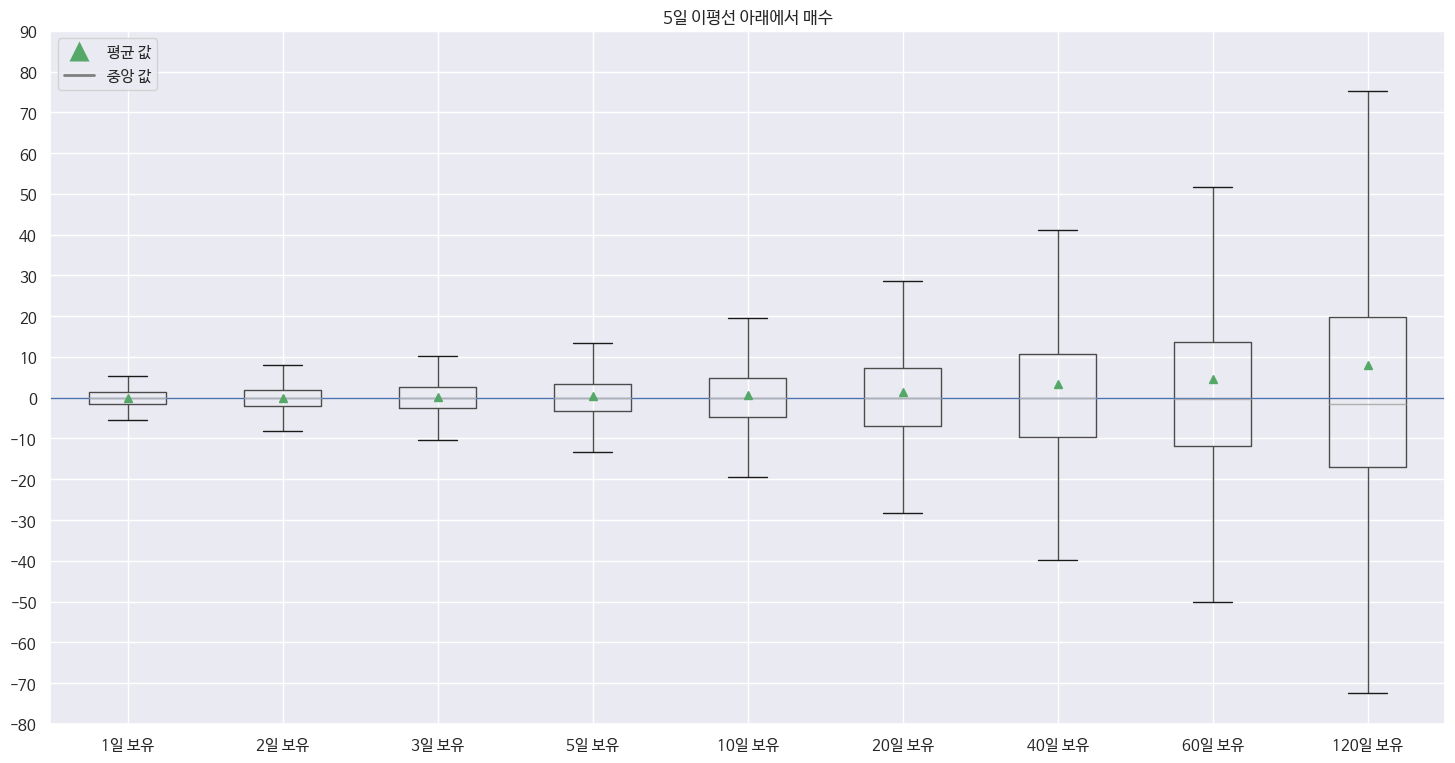

In [70]:
draw_meanmed_boxplot(exp['ret_lt_sma5d'], f'5일 이평선 아래에서 매수');

#### 5일 이평선 위에서 매수할 때

In [71]:
describe_and_aggperf(exp['ret_gt_sma5d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"880,976.0000","880,112.0000","879,468.0000","877,728.0000","874,228.0000","864,295.0000","843,173.0000","819,835.0000","755,101.0000"
mean,0.0020,0.0032,0.0041,0.0056,0.0099,0.0201,0.0331,0.0466,0.0850
std,0.0371,0.0538,0.0665,0.0874,0.1260,0.1811,0.2645,0.3281,0.4924
min,-0.4983,-0.5097,-0.5655,-0.6634,-0.9635,-0.9730,-0.9731,-0.9731,-0.9753
25%,-0.0140,-0.0207,-0.0262,-0.0345,-0.0493,-0.0691,-0.1004,-0.1240,-0.1729
50%,0.0000,-0.0012,-0.0018,-0.0025,-0.0024,-0.0022,-0.0040,-0.0043,-0.0128
75%,0.0125,0.0195,0.0245,0.0324,0.0486,0.0750,0.1083,0.1385,0.2083
max,1.0501,1.1916,1.1955,2.7073,3.4898,12.2667,8.7474,20.0688,18.4797
win_rate,0.5122,0.4975,0.4907,0.4871,0.4915,0.4955,0.4908,0.4921,0.4801
win_count,"451,218.0000","437,824.0000","431,589.0000","427,512.0000","429,707.0000","428,261.0000","413,842.0000","403,424.0000","362,510.0000"


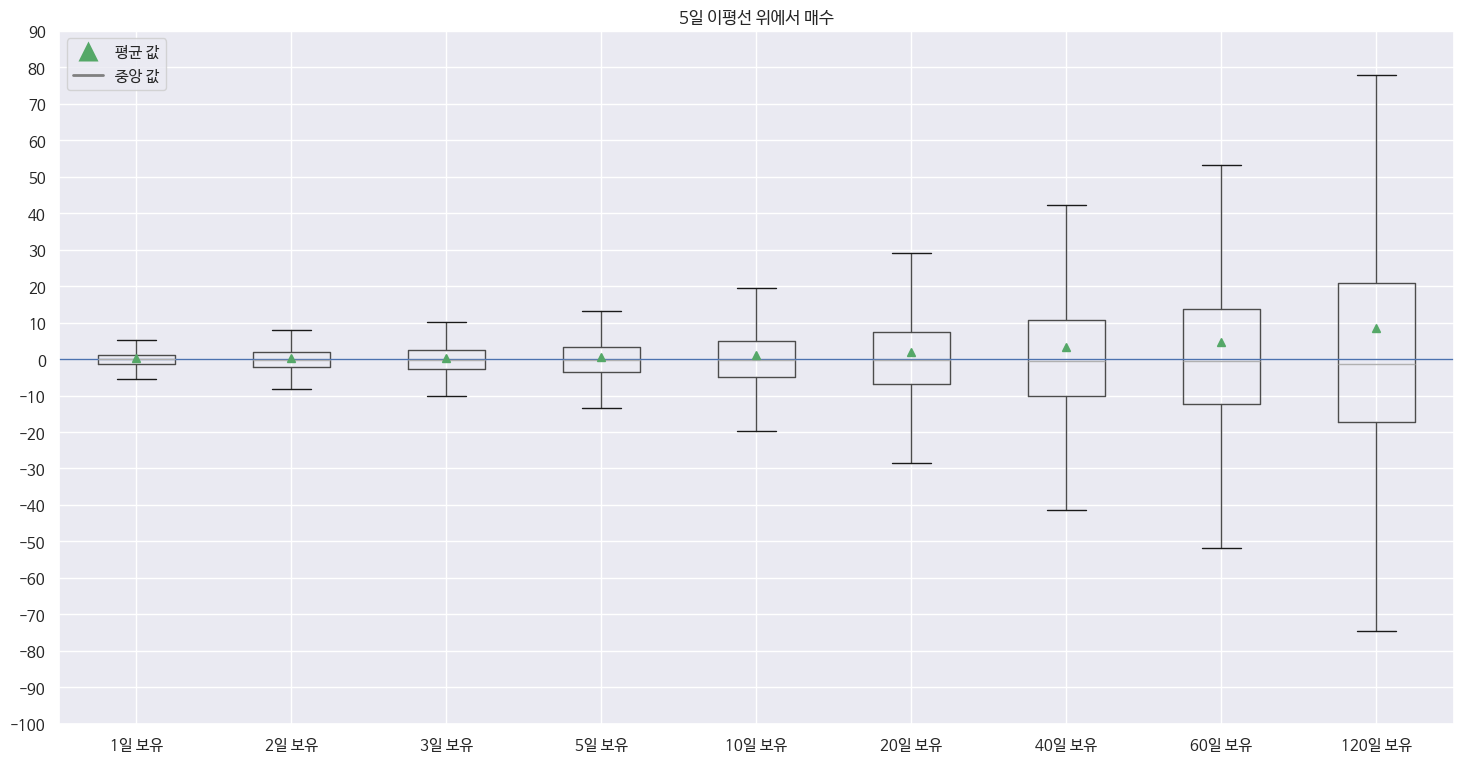

In [72]:
draw_meanmed_boxplot(exp['ret_gt_sma5d'], f'5일 이평선 위에서 매수');

#### 10일 이평선 아래에서 매수할 때

In [73]:
describe_and_aggperf(exp['ret_lt_sma10d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"946,869.0000","945,511.0000","943,969.0000","941,069.0000","933,870.0000","921,410.0000","900,454.0000","879,892.0000","819,197.0000"
mean,0.0000,0.0005,0.0013,0.0032,0.0068,0.0136,0.0331,0.0463,0.0811
std,0.0345,0.0500,0.0629,0.0834,0.1206,0.1747,0.2567,0.3245,0.4856
min,-0.9000,-0.9146,-0.9456,-0.9639,-0.9648,-0.9693,-0.9693,-0.9693,-0.9707
25%,-0.0140,-0.0206,-0.0255,-0.0330,-0.0481,-0.0697,-0.0935,-0.1174,-0.1672
50%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0038,-0.0132
75%,0.0129,0.0196,0.0251,0.0336,0.0483,0.0711,0.1065,0.1347,0.1980
max,1.1009,1.1669,1.1962,2.7031,3.7999,6.9387,13.6324,20.8197,20.3313
win_rate,0.5302,0.5134,0.5135,0.5110,0.5024,0.5009,0.5013,0.4933,0.4798
win_count,"501,999.0000","485,465.0000","484,757.0000","480,905.0000","469,143.0000","461,531.0000","451,365.0000","434,092.0000","393,025.0000"


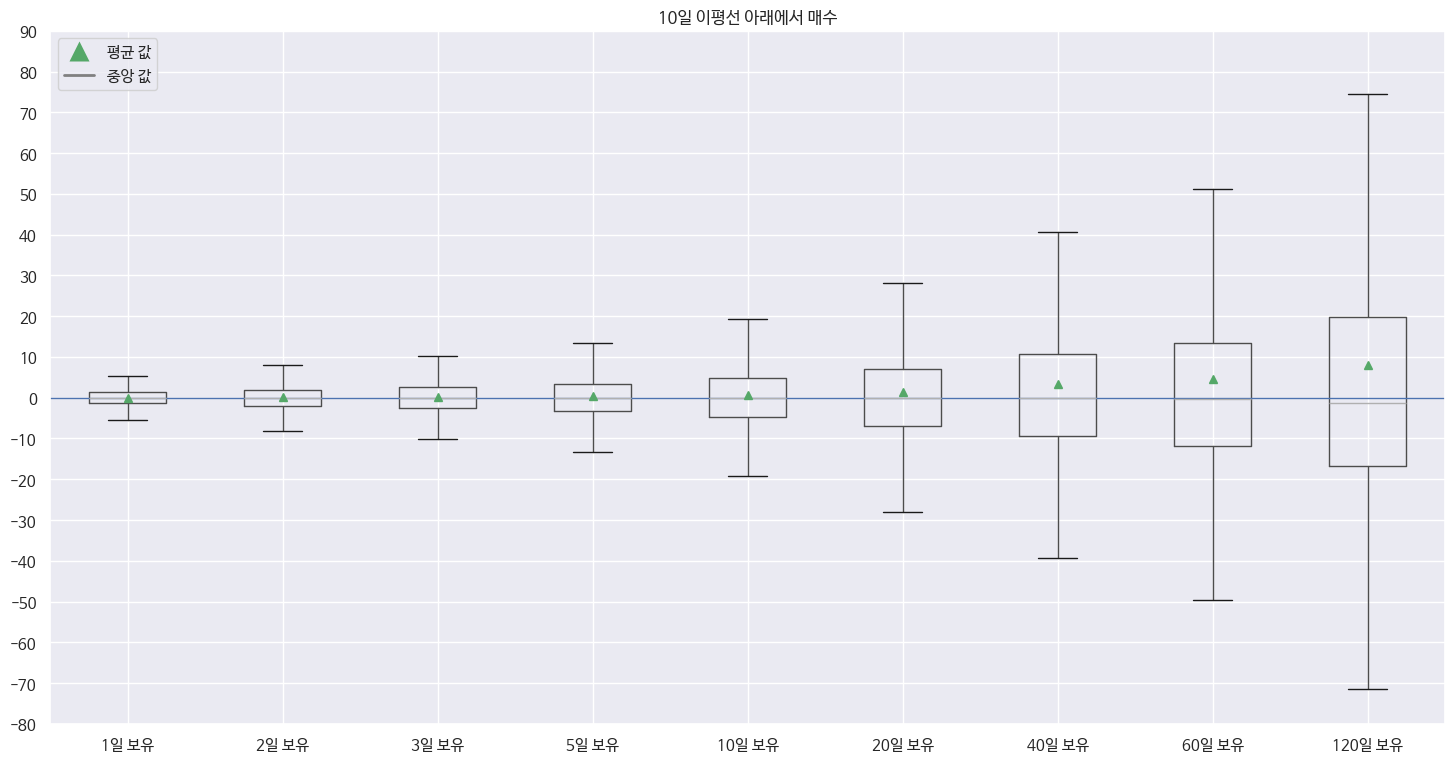

In [74]:
draw_meanmed_boxplot(exp['ret_lt_sma10d'], f'10일 이평선 아래에서 매수');

#### 10일 이평선 위에서 매수할 때

In [ ]:
describe_and_aggperf(exp['ret_gt_sma10d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"887,543.0000","886,736.0000","886,109.0000","884,678.0000","880,817.0000","871,252.0000","848,596.0000","825,706.0000","756,285.0000"
mean,0.0016,0.0029,0.0039,0.0056,0.0108,0.0202,0.0321,0.0459,0.0835
std,0.0373,0.0540,0.0670,0.0877,0.1250,0.1824,0.2660,0.3269,0.4925
min,-0.4983,-0.5064,-0.5655,-0.6413,-0.7559,-0.9730,-0.9731,-0.9731,-0.9753
25%,-0.0144,-0.0211,-0.0266,-0.0347,-0.0492,-0.0694,-0.1019,-0.1252,-0.1756
50%,0.0000,-0.0014,-0.0020,-0.0025,-0.0022,-0.0025,-0.0044,-0.0043,-0.0137
75%,0.0122,0.0192,0.0242,0.0320,0.0490,0.0751,0.1084,0.1386,0.2085
max,1.0501,1.1916,1.1960,3.3450,3.4898,12.2667,8.7474,15.2602,18.6030
win_rate,0.5085,0.4944,0.4889,0.4869,0.4936,0.4932,0.4897,0.4923,0.4788
win_count,"451,345.0000","438,388.0000","433,236.0000","430,714.0000","434,775.0000","429,666.0000","415,542.0000","406,480.0000","362,142.0000"


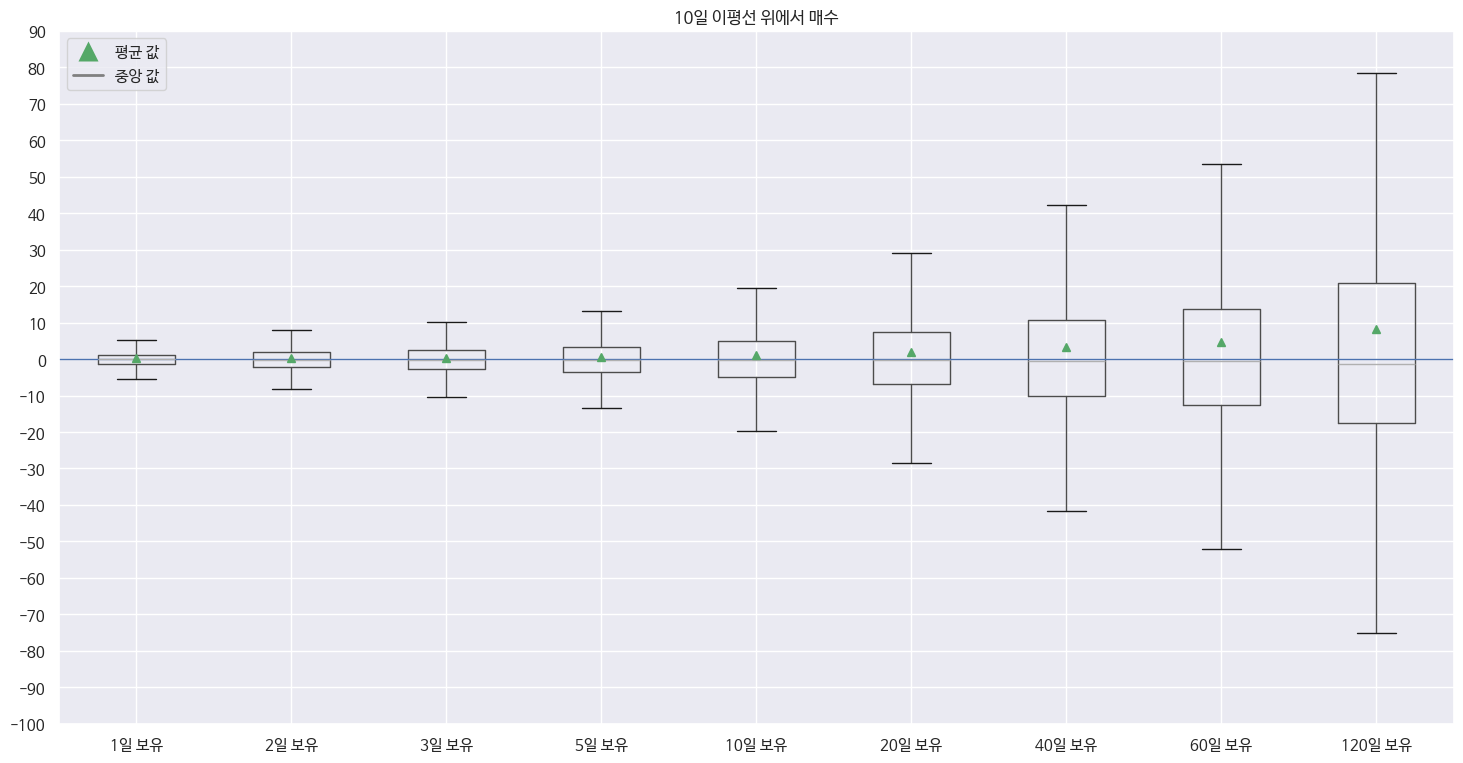

In [75]:
draw_meanmed_boxplot(exp['ret_gt_sma10d'], f'10일 이평선 위에서 매수');

#### 20일 이평선

In [76]:
describe_and_aggperf(exp['ret_lt_sma20d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"942,226.0000","940,775.0000","939,242.0000","936,272.0000","929,160.0000","917,255.0000","899,484.0000","877,046.0000","819,645.0000"
mean,0.0002,0.0007,0.0015,0.0031,0.0063,0.0155,0.0352,0.0479,0.0855
std,0.0341,0.0496,0.0627,0.0834,0.1212,0.1733,0.2559,0.3206,0.4850
min,-0.9000,-0.9146,-0.9456,-0.9639,-0.9648,-0.9692,-0.9678,-0.9678,-0.9897
25%,-0.0136,-0.0199,-0.0248,-0.0324,-0.0474,-0.0670,-0.0911,-0.1154,-0.1617
50%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0019,-0.0089
75%,0.0126,0.0193,0.0249,0.0332,0.0477,0.0727,0.1078,0.1365,0.2008
max,1.1009,1.1669,1.1962,2.7031,3.7999,6.9387,13.6324,20.0688,20.3313
win_rate,0.5311,0.5146,0.5141,0.5112,0.5052,0.5111,0.5058,0.4982,0.4866
win_count,"500,373.0000","484,083.0000","482,850.0000","478,654.0000","469,436.0000","468,773.0000","454,943.0000","436,928.0000","398,808.0000"


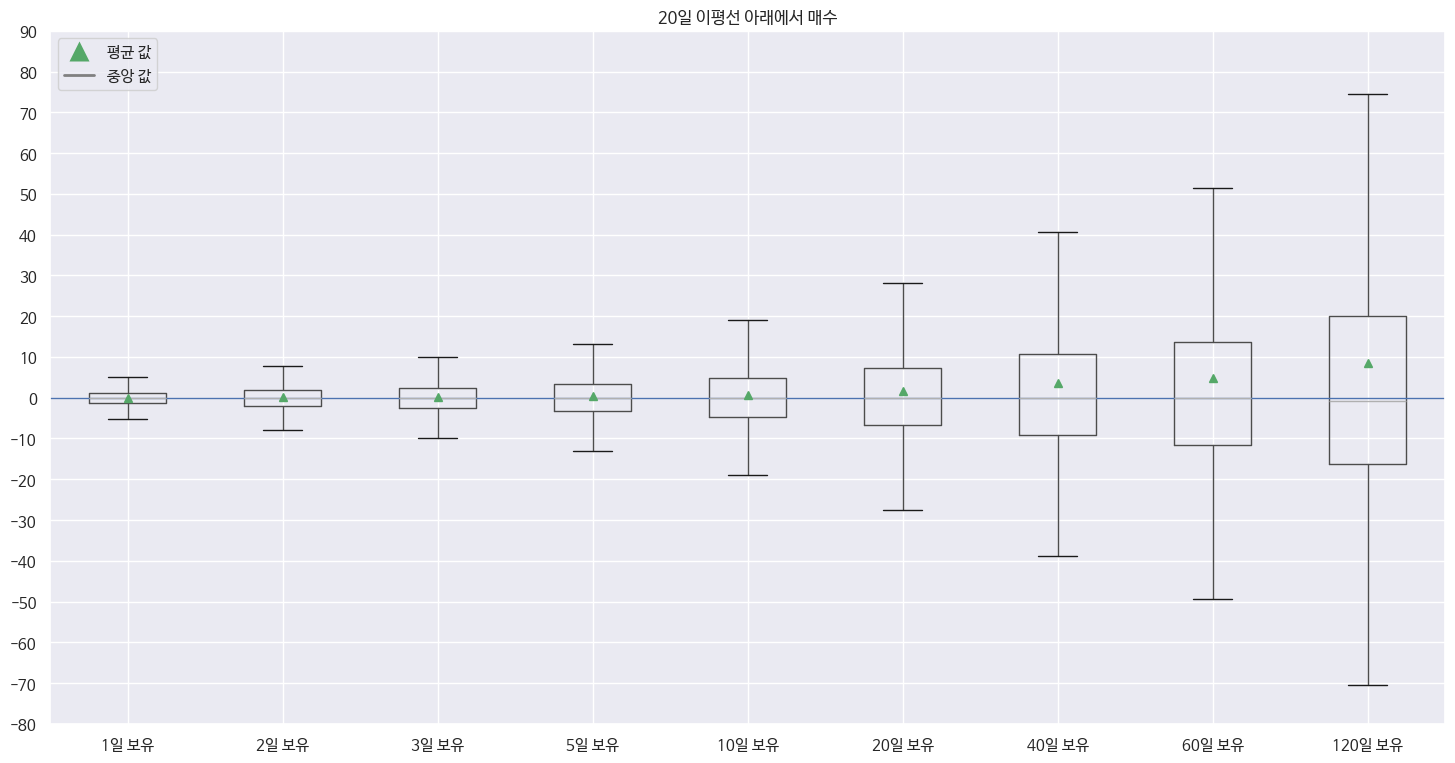

In [77]:
draw_meanmed_boxplot(exp['ret_lt_sma20d'], f'20일 이평선 아래에서 매수');

In [78]:
describe_and_aggperf(exp['ret_gt_sma20d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"888,629.0000","887,846.0000","887,144.0000","885,644.0000","881,583.0000","871,367.0000","845,331.0000","824,146.0000","750,907.0000"
mean,0.0014,0.0026,0.0036,0.0055,0.0106,0.0178,0.0292,0.0436,0.0787
std,0.0376,0.0543,0.0671,0.0875,0.1242,0.1837,0.2664,0.3268,0.4926
min,-0.5100,-0.5378,-0.5655,-0.6413,-0.7559,-0.9730,-0.9731,-0.9731,-0.9832
25%,-0.0148,-0.0217,-0.0271,-0.0353,-0.0500,-0.0720,-0.1047,-0.1272,-0.1810
50%,0.0000,-0.0013,-0.0018,-0.0024,-0.0026,-0.0048,-0.0057,-0.0058,-0.0172
75%,0.0125,0.0193,0.0243,0.0320,0.0486,0.0725,0.1059,0.1359,0.2053
max,1.0501,1.1916,1.1960,3.3450,3.4898,12.2667,7.9572,10.2871,18.6030
win_rate,0.5106,0.4959,0.4910,0.4884,0.4899,0.4832,0.4855,0.4884,0.4736
win_count,"453,703.0000","440,291.0000","435,614.0000","432,566.0000","431,861.0000","421,064.0000","410,376.0000","402,553.0000","355,629.0000"


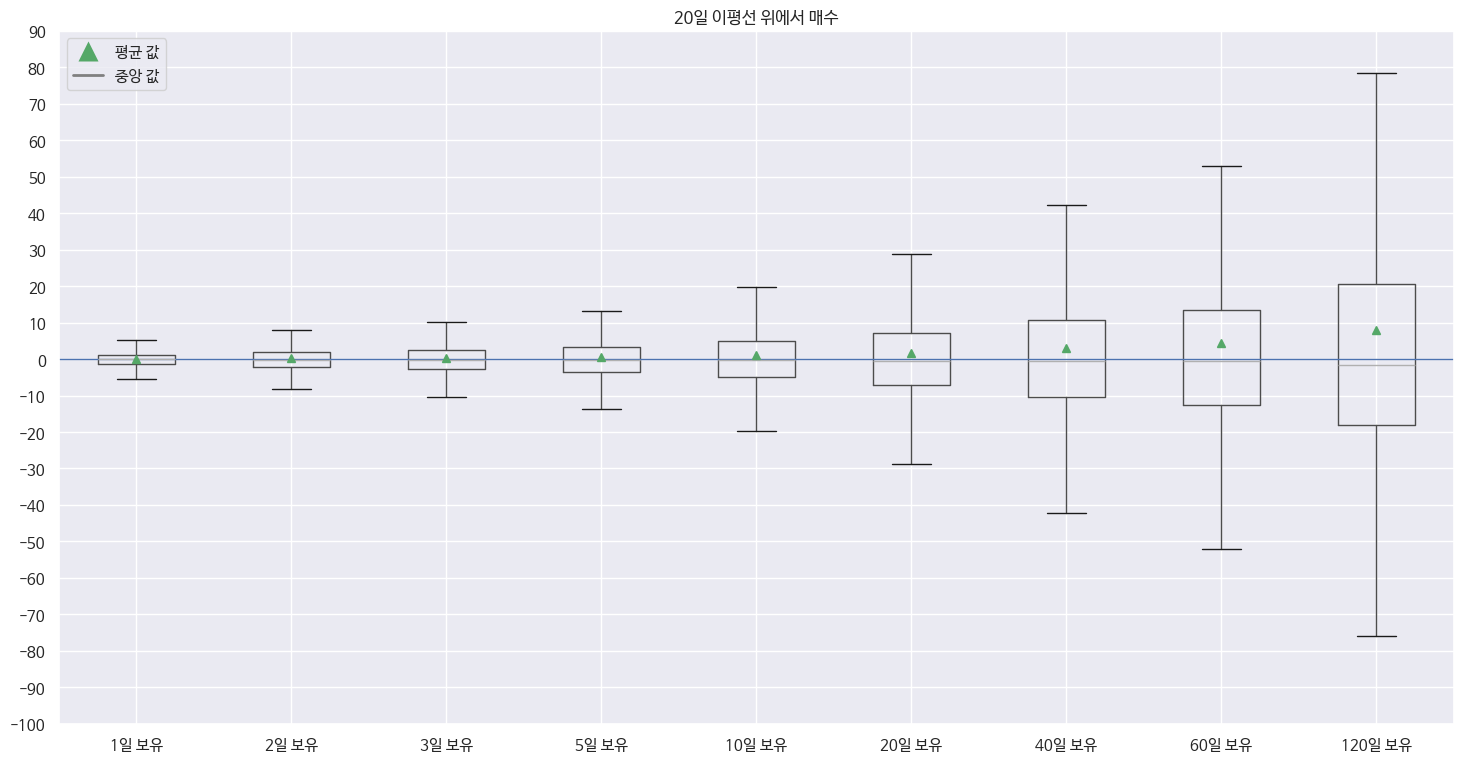

In [79]:
draw_meanmed_boxplot(exp['ret_gt_sma20d'], f'20일 이평선 위에서 매수');

#### 40일 이평선

In [80]:
describe_and_aggperf(exp['ret_lt_sma40d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"941,419.0000","940,045.0000","938,598.0000","935,857.0000","929,492.0000","919,687.0000","902,590.0000","882,494.0000","827,968.0000"
mean,0.0005,0.0012,0.0019,0.0036,0.0077,0.0178,0.0366,0.0468,0.0865
std,0.0335,0.0489,0.0617,0.0821,0.1191,0.1709,0.2532,0.3133,0.4750
min,-0.9498,-0.9498,-0.9550,-0.9692,-0.9692,-0.9639,-0.9639,-0.9639,-0.9897
25%,-0.0129,-0.0190,-0.0237,-0.0309,-0.0447,-0.0634,-0.0886,-0.1140,-0.1558
50%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0012,0.0000,0.0000,-0.0053
75%,0.0124,0.0191,0.0246,0.0329,0.0485,0.0749,0.1090,0.1359,0.1986
max,1.1009,1.1669,1.1951,2.7031,2.9896,9.4788,13.6324,11.1490,20.3313
win_rate,0.5372,0.5212,0.5207,0.5184,0.5159,0.5201,0.5117,0.5029,0.4922
win_count,"505,767.0000","489,996.0000","488,764.0000","485,176.0000","479,567.0000","478,291.0000","461,878.0000","443,807.0000","407,487.0000"


In [81]:
describe_and_aggperf(exp['ret_gt_sma40d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"873,503.0000","872,635.0000","871,838.0000","870,091.0000","865,241.0000","852,851.0000","826,064.0000","802,352.0000","725,976.0000"
mean,0.0009,0.0018,0.0027,0.0042,0.0086,0.0153,0.0273,0.0433,0.0791
std,0.0381,0.0549,0.0678,0.0884,0.1255,0.1856,0.2681,0.3274,0.5041
min,-0.5100,-0.5848,-0.5848,-0.7228,-0.9648,-0.9730,-0.9731,-0.9731,-0.9853
25%,-0.0157,-0.0228,-0.0285,-0.0371,-0.0525,-0.0750,-0.1068,-0.1284,-0.1865
50%,0.0000,-0.0019,-0.0025,-0.0033,-0.0043,-0.0062,-0.0070,-0.0071,-0.0181
75%,0.0123,0.0190,0.0238,0.0311,0.0464,0.0696,0.1039,0.1352,0.2106
max,0.9825,1.1916,1.1960,3.3450,3.7999,12.2667,7.5067,8.7810,18.6030
win_rate,0.5047,0.4884,0.4830,0.4790,0.4797,0.4774,0.4824,0.4859,0.4730
win_count,"440,814.0000","426,214.0000","421,137.0000","416,801.0000","415,084.0000","407,169.0000","398,524.0000","389,854.0000","343,419.0000"


#### 60일 이평선

In [82]:
describe_and_aggperf(exp['ret_lt_sma60d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"933,688.0000","932,506.0000","931,262.0000","928,914.0000","923,373.0000","914,222.0000","899,073.0000","882,744.0000","831,231.0000"
mean,0.0006,0.0014,0.0024,0.0042,0.0085,0.0188,0.0361,0.0453,0.0839
std,0.0333,0.0486,0.0612,0.0814,0.1180,0.1707,0.2517,0.3076,0.4699
min,-0.7377,-0.8094,-0.8700,-0.9215,-0.9529,-0.9529,-0.9550,-0.9611,-0.9897
25%,-0.0125,-0.0185,-0.0230,-0.0299,-0.0433,-0.0616,-0.0872,-0.1125,-0.1550
50%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0012,0.0000,0.0000,-0.0046
75%,0.0122,0.0189,0.0245,0.0328,0.0485,0.0750,0.1083,0.1334,0.1951
max,1.0501,1.1058,1.1951,2.7019,3.1270,12.2667,13.6324,11.1490,20.3313
win_rate,0.5389,0.5238,0.5236,0.5219,0.5202,0.5244,0.5155,0.5055,0.4937
win_count,"503,198.0000","488,453.0000","487,652.0000","484,778.0000","480,328.0000","479,405.0000","463,485.0000","446,192.0000","410,350.0000"


In [83]:
describe_and_aggperf(exp['ret_gt_sma60d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"863,583.0000","862,519.0000","861,517.0000","859,375.0000","853,687.0000","840,611.0000","811,768.0000","784,059.0000","704,672.0000"
mean,0.0009,0.0018,0.0026,0.0042,0.0082,0.0146,0.0282,0.0442,0.0847
std,0.0382,0.0550,0.0680,0.0888,0.1265,0.1858,0.2683,0.3307,0.5117
min,-0.9498,-0.9498,-0.9550,-0.9692,-0.9692,-0.9730,-0.9731,-0.9731,-0.9853
25%,-0.0157,-0.0228,-0.0285,-0.0372,-0.0532,-0.0759,-0.1068,-0.1297,-0.1851
50%,0.0000,-0.0016,-0.0023,-0.0029,-0.0041,-0.0060,-0.0065,-0.0071,-0.0148
75%,0.0126,0.0193,0.0241,0.0315,0.0464,0.0696,0.1047,0.1372,0.2187
max,0.9825,1.1916,1.1960,3.3450,3.7999,6.5226,7.4129,10.9448,18.6030
win_rate,0.5085,0.4924,0.4871,0.4830,0.4811,0.4785,0.4838,0.4862,0.4785
win_count,"439,137.0000","424,682.0000","419,676.0000","415,065.0000","410,676.0000","402,204.0000","392,706.0000","381,238.0000","337,155.0000"


#### 120일 이평선

In [84]:
describe_and_aggperf(exp['ret_lt_sma120d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"917,282.0000","916,467.0000","915,620.0000","913,999.0000","910,153.0000","903,563.0000","890,895.0000","876,623.0000","836,872.0000"
mean,0.0007,0.0015,0.0024,0.0043,0.0088,0.0178,0.0316,0.0409,0.0800
std,0.0332,0.0485,0.0611,0.0808,0.1161,0.1671,0.2427,0.2959,0.4634
min,-0.7377,-0.8094,-0.8700,-0.9215,-0.9588,-0.9897,-0.9897,-0.9897,-0.9897
25%,-0.0122,-0.0181,-0.0226,-0.0292,-0.0421,-0.0607,-0.0866,-0.1106,-0.1544
50%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0020
75%,0.0118,0.0184,0.0238,0.0321,0.0480,0.0735,0.1032,0.1280,0.1902
max,1.0501,1.1058,1.1950,2.7019,2.9896,6.9387,13.6324,8.8712,20.3313
win_rate,0.5427,0.5284,0.5278,0.5270,0.5276,0.5295,0.5172,0.5100,0.4986
win_count,"497,783.0000","484,220.0000","483,232.0000","481,650.0000","480,218.0000","478,444.0000","460,806.0000","447,076.0000","417,235.0000"


<Axes: title={'center': '120일선 아래에서 매수'}>

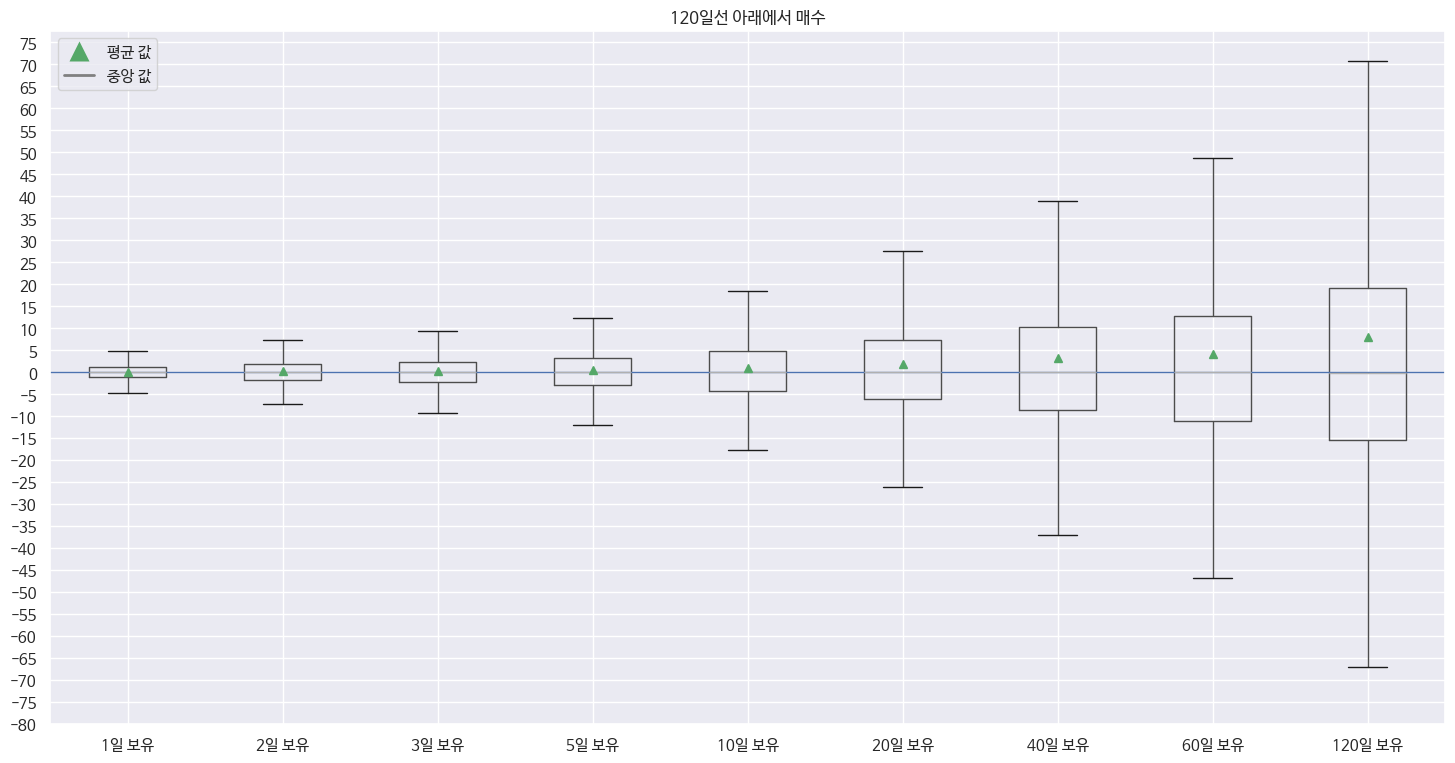

In [85]:
draw_meanmed_boxplot(exp['ret_lt_sma120d'], '120일선 아래에서 매수')

In [86]:
describe_and_aggperf(exp['ret_gt_sma120d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"823,421.0000","821,990.0000","820,591.0000","817,720.0000","810,341.0000","794,641.0000","763,048.0000","733,345.0000","642,793.0000"
mean,0.0008,0.0016,0.0024,0.0040,0.0079,0.0147,0.0295,0.0463,0.0967
std,0.0382,0.0550,0.0681,0.0893,0.1282,0.1887,0.2730,0.3390,0.5288
min,-0.9498,-0.9498,-0.9550,-0.9692,-0.9727,-0.9832,-0.9853,-0.9853,-0.9853
25%,-0.0158,-0.0231,-0.0288,-0.0375,-0.0537,-0.0767,-0.1083,-0.1315,-0.1819
50%,0.0000,-0.0014,-0.0020,-0.0026,-0.0037,-0.0054,-0.0059,-0.0067,-0.0068
75%,0.0128,0.0195,0.0243,0.0318,0.0468,0.0703,0.1074,0.1424,0.2378
max,0.9825,1.1916,1.1960,3.3450,3.7999,12.2667,13.2143,11.1490,18.6030
win_rate,0.5122,0.4954,0.4903,0.4862,0.4840,0.4811,0.4858,0.4875,0.4917
win_count,"421,716.0000","407,214.0000","402,362.0000","397,572.0000","392,187.0000","382,340.0000","370,699.0000","357,523.0000","316,039.0000"


<Axes: title={'center': '120일선 위에서 매수'}>

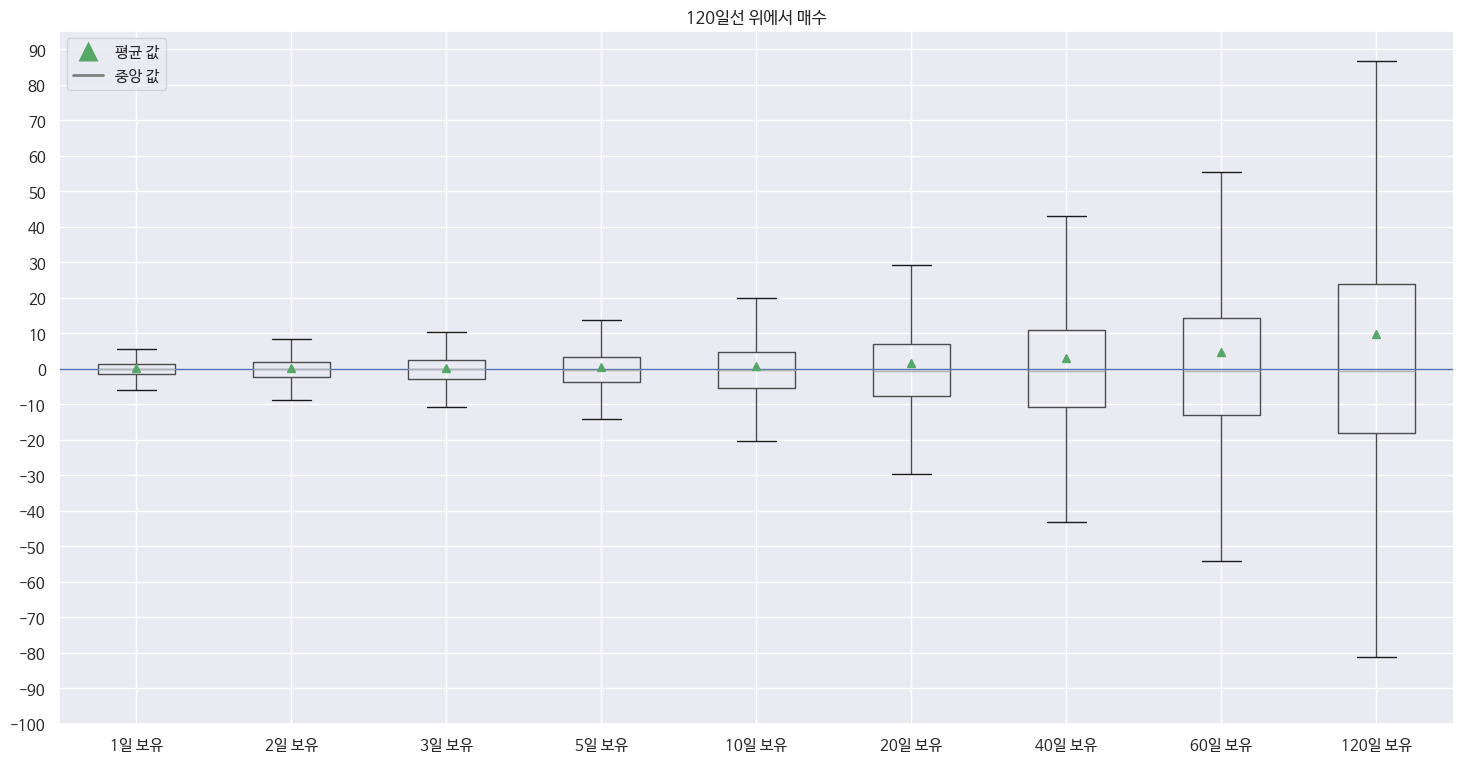

In [87]:
draw_meanmed_boxplot(exp['ret_gt_sma120d'], '120일선 위에서 매수')

## 이평선을 이용한 투자전략2: 정배열에서 매수할때, 역배열에서 매수할 때##

In [88]:
allsma_df = pd.DataFrame({f'adj_close_sma{win}d': d[f'adj_close_sma{win}d'].stack(dropna=False) for win in sma_winli})

allsma_df.insert(0, 'adj_close', d['adj_close'].stack(dropna=False))

/tmp/ipykernel_598/4215736330.py:1: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  allsma_df = pd.DataFrame({f'adj_close_sma{win}d': d[f'adj_close_sma{win}d'].stack(dropna=False) for win in sma_winli})
/tmp/ipykernel_598/4215736330.py:1: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  allsma_df = pd.DataFrame({f'adj_close_sma{win}d': d[f'adj_close_sma{win}d'].stack(dropna=False) for win in sma_winli})
/tmp/ipykernel_598/4215736330.py:1: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New no

In [89]:
allsma_df

adj_close  adj_close_sma5d  adj_close_sma10d  \
Symbol                                                              
A000020 2018-01-02  9,870.0000              NaN               NaN   
        2018-01-03 10,000.0000       9,935.0000               NaN   
        2018-01-04  9,750.0000       9,873.3333               NaN   
        2018-01-05  9,910.0000       9,882.5000               NaN   
        2018-01-08  9,950.0000       9,896.0000        9,896.0000   
...                        ...              ...               ...   
A950220 2021-07-26 10,700.0000      10,490.0000       10,505.0000   
        2021-07-27 10,400.0000      10,490.0000       10,485.0000   
        2021-07-28 10,350.0000      10,490.0000       10,470.0000   
        2021-07-29 10,300.0000      10,450.0000       10,445.0000   
        2021-07-30 10,150.0000      10,380.0000       10,410.0000   

                    adj_close_sma20d  adj_close_sma40d  adj_close_sma60d  \
Symbol                                                                     
A000020 2018-01-02               NaN               NaN               NaN   
        2018-01-03               NaN               NaN               NaN   
        2018-01-04               NaN               NaN               NaN   
        2018-01-05               NaN               NaN               NaN   
        2018-01-08               NaN               NaN               NaN   
...                              ...               ...               ...   
A950220 2021-07-26       10,772.5000       10,976.2500       11,331.6667   
        2021-07-27       10,760.0000       10,933.7500       11,281.6667   
        2021-07-28       10,745.0000       10,893.7500       11,245.0000   
        2021-07-29       10,692.5000       10,850.0000       11,212.5000   
        2021-07-30       10,632.5000       10,801.2500       11,182.5000   

                    adj_close_sma120d  
Symbol                                 
A000020 2018-01-02                NaN  
        2018-01-03                NaN  
        2018-01-04                NaN  
        2018-01-05                NaN  
        2018-01-08                NaN  
...                               ...  
A950220 2021-07-26        11,757.1429  
        2021-07-27        11,742.3913  
        2021-07-28        11,727.4194  
        2021-07-29        11,712.2340  
        2021-07-30        11,695.7895  

[2115668 rows x 7 columns]

In [90]:
_cn_li = allsma_df.columns

_qrli = list()
_inv_qrli = list()
for i, cn in enumerate(_cn_li):
    if i > 0:
        _qrli.append(f"{_cn_li[i-1]} >= {_cn_li[i]}")
        _inv_qrli.append(f"{_cn_li[i-1]} <= {_cn_li[i]}")
_qr = ' and '.join(_qrli)
_inv_qr = ' and '.join(_inv_qrli)

In [91]:
# 정배열 쿼리
_qr

'adj_close >= adj_close_sma5d and adj_close_sma5d >= adj_close_sma10d and adj_close_sma10d >= adj_close_sma20d and adj_close_sma20d >= adj_close_sma40d and adj_close_sma40d >= adj_close_sma60d and adj_close_sma60d >= adj_close_sma120d'

In [92]:
# 역배열 쿼리
_inv_qr

'adj_close <= adj_close_sma5d and adj_close_sma5d <= adj_close_sma10d and adj_close_sma10d <= adj_close_sma20d and adj_close_sma20d <= adj_close_sma40d and adj_close_sma40d <= adj_close_sma60d and adj_close_sma60d <= adj_close_sma120d'

In [93]:
allsma_df.shape

(2115668, 7)

In [94]:
aligned_midxs = allsma_df.query(_qr).index
inv_aligned_midxs = allsma_df.query(_inv_qr).index
other_midxs = set(allsma_df.index) - set(aligned_midxs) - set(inv_aligned_midxs)

In [96]:
exp['ret_sma_aligned'] = get_all_return_df_by(d, aligned_midxs)
exp['ret_sma_inverse_aligned'] = get_all_return_df_by(d, inv_aligned_midxs)
exp['ret_sma_not_aligned'] = get_all_return_df_by(d, list(other_midxs))

/tmp/ipykernel_598/1174398668.py:4: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  return pd.concat([pd.Series(d[f'close_return_{hold_day}d'].stack(dropna=False).loc[midxs], name=f'{hold_day}일 보유') for hold_day in hold_day_li], axis=1)
/tmp/ipykernel_598/1174398668.py:4: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  return pd.concat([pd.Series(d[f'close_return_{hold_day}d'].stack(dropna=False).loc[midxs], name=f'{hold_day}일 보유') for hold_day in hold_day_li], axis=1)
/tmp/ipykernel_598/1174398668.py:4: FutureWarning: The previous implementation of stack is deprecated and 

#### 이평선 정배열에서 매수할 때

In [97]:
exp['ret_sma_aligned'].describe()

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"175,747.0000","175,493.0000","175,251.0000","174,742.0000","173,371.0000","170,042.0000","162,226.0000","154,208.0000","129,725.0000"
mean,0.0007,0.0010,0.0011,0.0015,0.0035,0.0057,0.0073,0.0134,0.0376
std,0.0403,0.0578,0.0704,0.0904,0.1236,0.1720,0.2393,0.2905,0.4606
min,-0.9732,-0.9753,-0.9829,-0.9932,-0.9932,-0.9932,-0.9932,-0.9932,-0.9932
25%,-0.0047,-0.0085,-0.0115,-0.0151,-0.0205,-0.0318,-0.0475,-0.0608,-0.1032
50%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
75%,0.0000,0.0000,0.0000,0.0000,0.0024,0.0044,0.0099,0.0192,0.0430
max,1.9080,1.9080,2.0272,3.3450,3.4898,3.9525,6.0597,7.7301,15.0250


In [98]:
describe_and_aggperf(exp['ret_sma_aligned'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"175,747.0000","175,493.0000","175,251.0000","174,742.0000","173,371.0000","170,042.0000","162,226.0000","154,208.0000","129,725.0000"
mean,0.0007,0.0010,0.0011,0.0015,0.0035,0.0057,0.0073,0.0134,0.0376
std,0.0403,0.0578,0.0704,0.0904,0.1236,0.1720,0.2393,0.2905,0.4606
min,-0.9732,-0.9753,-0.9829,-0.9932,-0.9932,-0.9932,-0.9932,-0.9932,-0.9932
25%,-0.0047,-0.0085,-0.0115,-0.0151,-0.0205,-0.0318,-0.0475,-0.0608,-0.1032
50%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
75%,0.0000,0.0000,0.0000,0.0000,0.0024,0.0044,0.0099,0.0192,0.0430
max,1.9080,1.9080,2.0272,3.3450,3.4898,3.9525,6.0597,7.7301,15.0250
win_rate,0.7137,0.7014,0.6937,0.6894,0.6924,0.6867,0.6822,0.6811,0.6720
win_count,"125,434.0000","123,095.0000","121,576.0000","120,465.0000","120,049.0000","116,770.0000","110,670.0000","105,033.0000","87,176.0000"


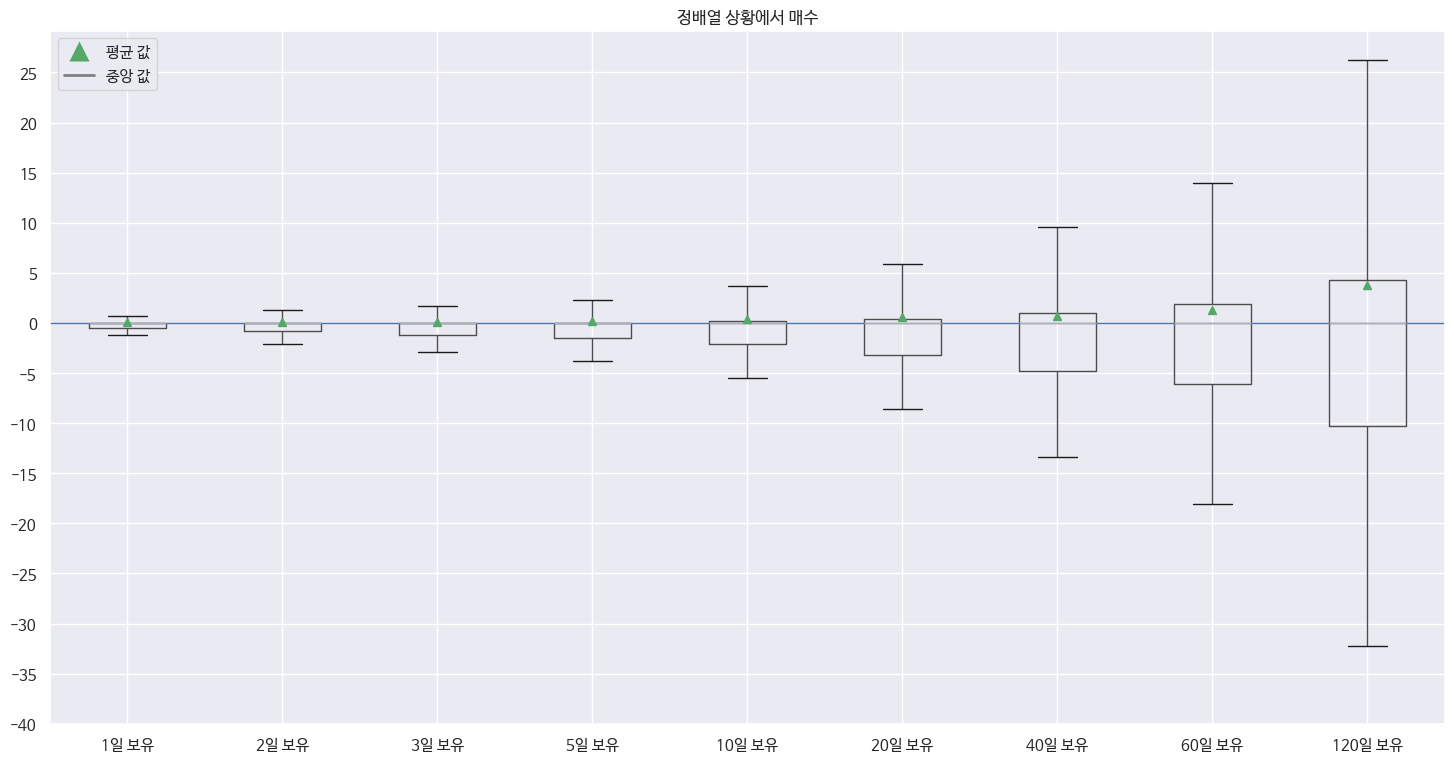

In [99]:
draw_meanmed_boxplot(exp['ret_sma_aligned'], f'정배열 상황에서 매수');

#### 이평선 역배열에서 매수할 때

In [100]:
exp['ret_sma_inverse_aligned'].describe()

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"207,119.0000","206,845.0000","206,549.0000","206,003.0000","204,722.0000","202,407.0000","197,879.0000","192,894.0000","178,387.0000"
mean,-0.0017,-0.0020,-0.0016,-0.0004,0.0037,0.0113,0.0249,0.0307,0.0523
std,0.0355,0.0515,0.0649,0.0853,0.1181,0.1662,0.2287,0.2792,0.4318
min,-0.9732,-0.9753,-0.9829,-0.9932,-0.9932,-0.9932,-0.9932,-0.9932,-0.9932
25%,-0.0033,-0.0054,-0.0060,-0.0077,-0.0107,-0.0139,-0.0227,-0.0382,-0.0741
50%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
75%,0.0016,0.0032,0.0050,0.0076,0.0133,0.0248,0.0391,0.0531,0.0831
max,1.9080,1.9080,2.0272,2.0612,2.9896,3.5056,5.7945,5.8320,11.8075


In [101]:
describe_and_aggperf(exp['ret_sma_inverse_aligned'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"207,119.0000","206,845.0000","206,549.0000","206,003.0000","204,722.0000","202,407.0000","197,879.0000","192,894.0000","178,387.0000"
mean,-0.0017,-0.0020,-0.0016,-0.0004,0.0037,0.0113,0.0249,0.0307,0.0523
std,0.0355,0.0515,0.0649,0.0853,0.1181,0.1662,0.2287,0.2792,0.4318
min,-0.9732,-0.9753,-0.9829,-0.9932,-0.9932,-0.9932,-0.9932,-0.9932,-0.9932
25%,-0.0033,-0.0054,-0.0060,-0.0077,-0.0107,-0.0139,-0.0227,-0.0382,-0.0741
50%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
75%,0.0016,0.0032,0.0050,0.0076,0.0133,0.0248,0.0391,0.0531,0.0831
max,1.9080,1.9080,2.0272,2.0612,2.9896,3.5056,5.7945,5.8320,11.8075
win_rate,0.7236,0.7164,0.7203,0.7191,0.7190,0.7210,0.7120,0.6990,0.6689
win_count,"149,869.0000","148,181.0000","148,771.0000","148,135.0000","147,195.0000","145,942.0000","140,894.0000","134,829.0000","119,330.0000"


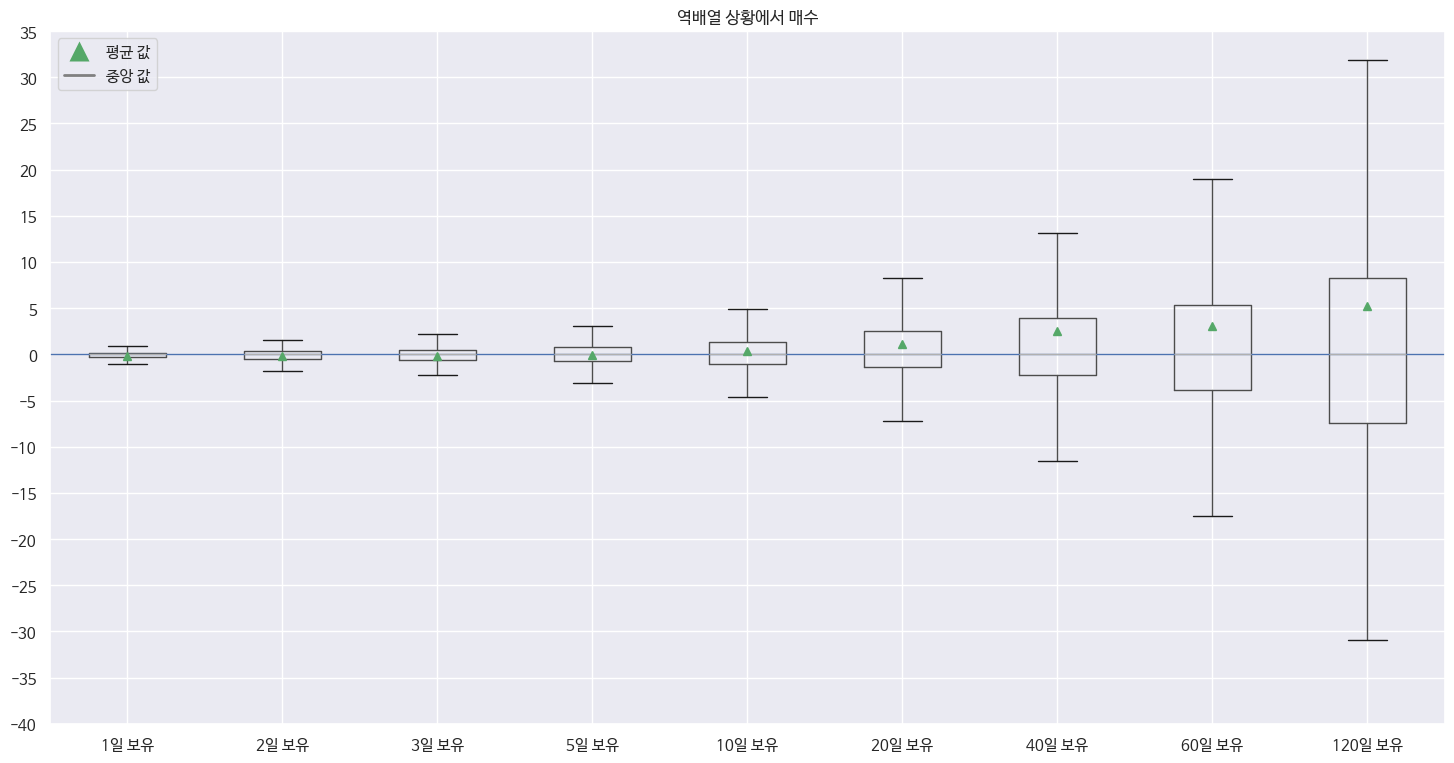

In [102]:
draw_meanmed_boxplot(exp['ret_sma_inverse_aligned'], f'역배열 상황에서 매수');

#### 정배열도 아니고 역배열도 아닌 상황에서 매수할 때

In [103]:
exp['ret_sma_not_aligned'].describe()

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"1,637,728.0000","1,635,733.0000","1,633,748.0000","1,629,758.0000","1,619,803.0000","1,600,120.0000","1,561,653.0000","1,523,984.0000","1,411,709.0000"
mean,0.0010,0.0020,0.0029,0.0046,0.0086,0.0165,0.0314,0.0448,0.0779
std,0.0342,0.0497,0.0622,0.0822,0.1191,0.1746,0.2578,0.3233,0.4824
min,-0.9498,-0.9498,-0.9550,-0.9692,-0.9692,-0.9706,-0.9714,-0.9706,-0.9853
25%,-0.0137,-0.0200,-0.0250,-0.0327,-0.0472,-0.0678,-0.0962,-0.1199,-0.1722
50%,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0012,-0.0025,-0.0042,-0.0155
75%,0.0124,0.0190,0.0242,0.0322,0.0476,0.0716,0.1049,0.1333,0.1967
max,1.1009,1.1669,1.1962,2.7031,3.7999,12.2667,13.6324,20.8197,20.3313


In [104]:
describe_and_aggperf(exp['ret_sma_not_aligned'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"1,637,728.0000","1,635,733.0000","1,633,748.0000","1,629,758.0000","1,619,803.0000","1,600,120.0000","1,561,653.0000","1,523,984.0000","1,411,709.0000"
mean,0.0010,0.0020,0.0029,0.0046,0.0086,0.0165,0.0314,0.0448,0.0779
std,0.0342,0.0497,0.0622,0.0822,0.1191,0.1746,0.2578,0.3233,0.4824
min,-0.9498,-0.9498,-0.9550,-0.9692,-0.9692,-0.9706,-0.9714,-0.9706,-0.9853
25%,-0.0137,-0.0200,-0.0250,-0.0327,-0.0472,-0.0678,-0.0962,-0.1199,-0.1722
50%,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0012,-0.0025,-0.0042,-0.0155
75%,0.0124,0.0190,0.0242,0.0322,0.0476,0.0716,0.1049,0.1333,0.1967
max,1.1009,1.1669,1.1962,2.7031,3.7999,12.2667,13.6324,20.8197,20.3313
win_rate,0.5234,0.5077,0.5050,0.5026,0.5004,0.4994,0.4956,0.4924,0.4759
win_count,"857,173.0000","830,502.0000","825,054.0000","819,111.0000","810,522.0000","799,063.0000","773,997.0000","750,372.0000","671,858.0000"


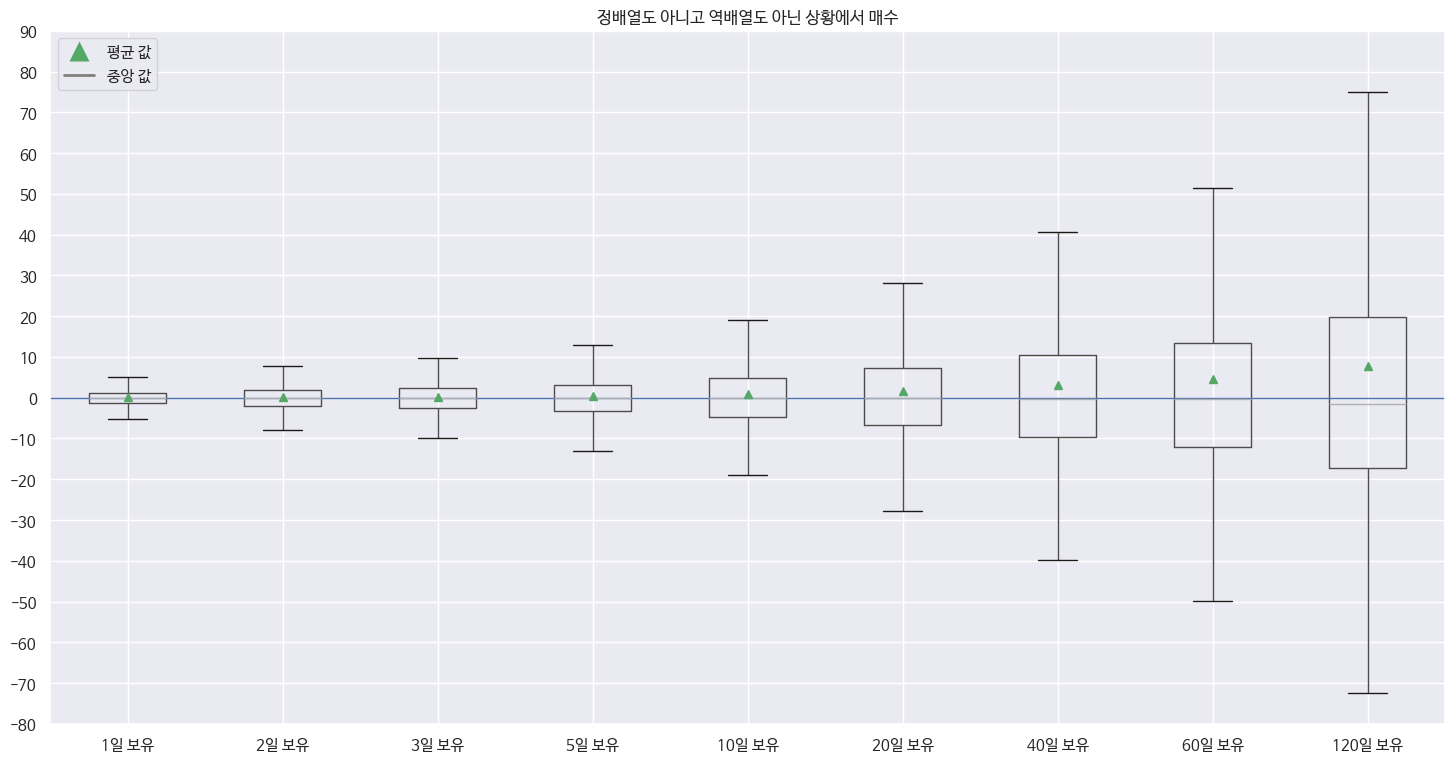

In [105]:
draw_meanmed_boxplot(exp['ret_sma_not_aligned'], f'정배열도 아니고 역배열도 아닌 상황에서 매수');

## 이평선을 이용한 투자전략3: 골든크로스 발생 시점에 매수할 때

In [106]:
d['adj_close__l1d'] = d['adj_close'].shift(1, axis=1)

In [107]:
for win in sma_winli:
    d[f'adj_close_sma{win}d__l1d'] = d[f'adj_close_sma{win}d'].shift(1, axis=1)

In [108]:
master_midxs = d['adj_close'].stack(dropna=False).index

for win in sma_winli:
    golden_cross_idxs = master_midxs[((d[f'adj_close__l1d'] < d[f'adj_close_sma{win}d__l1d']) & (d[f'adj_close'] > d[f'adj_close_sma{win}d'])).stack(dropna=False)]
    exp[f'ret_goldencross_sma{win}d'] = get_all_return_df_by(d, golden_cross_idxs)

/tmp/ipykernel_598/2413793215.py:1: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  master_midxs = d['adj_close'].stack(dropna=False).index
/tmp/ipykernel_598/2413793215.py:4: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  golden_cross_idxs = master_midxs[((d[f'adj_close__l1d'] < d[f'adj_close_sma{win}d__l1d']) & (d[f'adj_close'] > d[f'adj_close_sma{win}d'])).stack(dropna=False)]
/tmp/ipykernel_598/1174398668.py:4: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 f

In [109]:
exp.keys()

dict_keys(['ret_lt_sma5d', 'ret_gt_sma5d', 'ret_lt_sma10d', 'ret_gt_sma10d', 'ret_lt_sma20d', 'ret_gt_sma20d', 'ret_lt_sma40d', 'ret_gt_sma40d', 'ret_lt_sma60d', 'ret_gt_sma60d', 'ret_lt_sma120d', 'ret_gt_sma120d', 'ret_sma_aligned', 'ret_sma_inverse_aligned', 'ret_sma_not_aligned', 'ret_goldencross_sma5d', 'ret_goldencross_sma10d', 'ret_goldencross_sma20d', 'ret_goldencross_sma40d', 'ret_goldencross_sma60d', 'ret_goldencross_sma120d'])

In [110]:
describe_and_aggperf(exp['ret_goldencross_sma5d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"228,395.0000","228,041.0000","227,882.0000","227,368.0000","226,055.0000","223,190.0000","217,546.0000","212,324.0000","196,451.0000"
mean,0.0027,0.0043,0.0052,0.0072,0.0099,0.0172,0.0305,0.0430,0.0774
std,0.0357,0.0521,0.0646,0.0842,0.1242,0.1780,0.2580,0.3266,0.4842
min,-0.3806,-0.5064,-0.5618,-0.6634,-0.9514,-0.9678,-0.9678,-0.9678,-0.9753
25%,-0.0131,-0.0190,-0.0244,-0.0324,-0.0476,-0.0689,-0.0982,-0.1228,-0.1732
50%,0.0000,0.0000,0.0000,0.0000,-0.0016,-0.0024,-0.0047,-0.0072,-0.0170
75%,0.0132,0.0205,0.0258,0.0338,0.0486,0.0718,0.1026,0.1311,0.1958
max,0.6116,0.7407,1.1948,2.6992,3.4898,9.4788,8.7474,20.0688,18.4797
win_rate,0.5201,0.5122,0.5059,0.5001,0.4965,0.4946,0.4879,0.4845,0.4728
win_count,"118,780.0000","116,799.0000","115,278.0000","113,699.0000","112,237.0000","110,392.0000","106,145.0000","102,879.0000","92,884.0000"


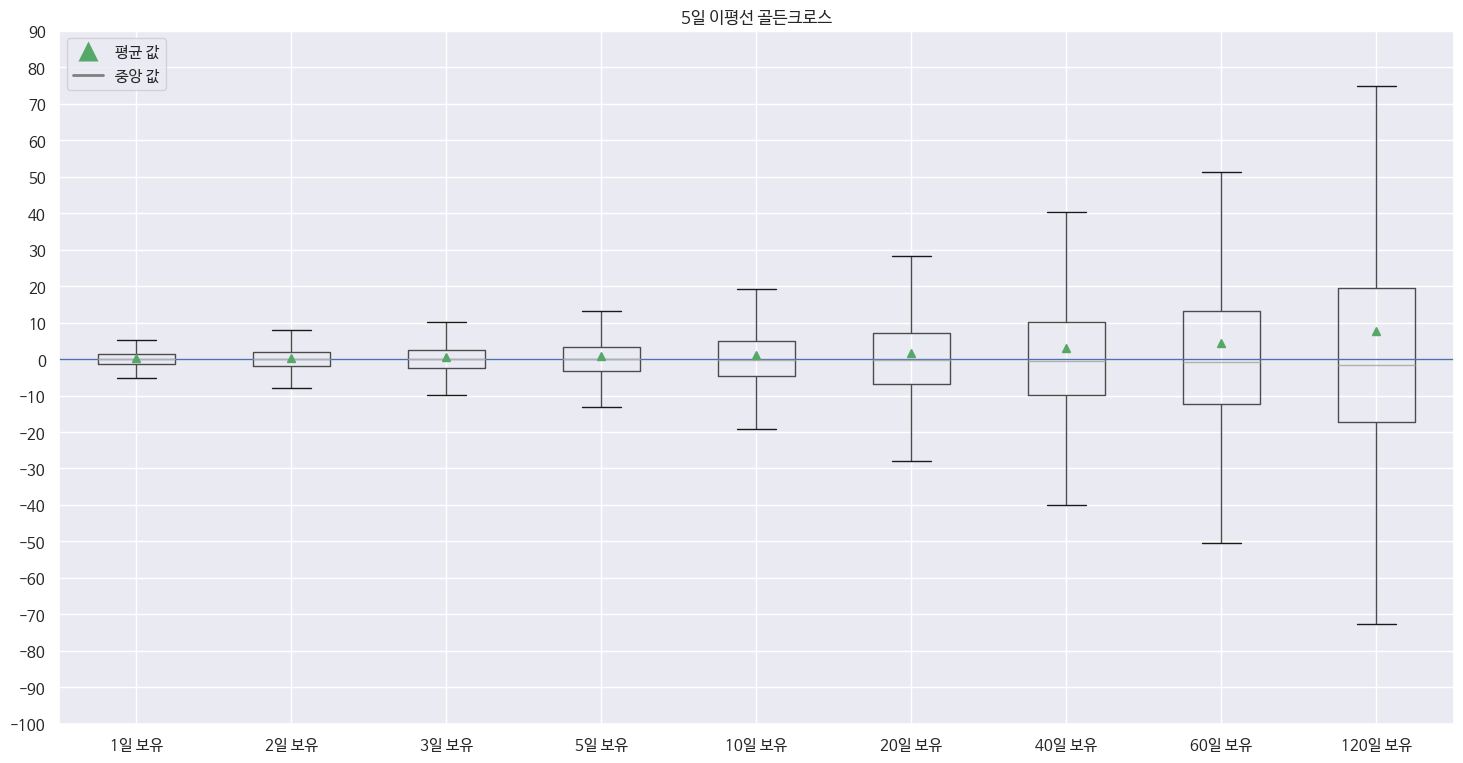

In [111]:
draw_meanmed_boxplot(exp['ret_goldencross_sma5d'], '5일 이평선 골든크로스');

In [112]:
describe_and_aggperf(exp['ret_goldencross_sma20d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"101,151.0000","101,004.0000","100,920.0000","100,709.0000","100,267.0000","99,080.0000","96,695.0000","94,015.0000","87,066.0000"
mean,0.0027,0.0046,0.0056,0.0072,0.0117,0.0185,0.0296,0.0376,0.0767
std,0.0372,0.0532,0.0650,0.0842,0.1205,0.1749,0.2581,0.3189,0.4768
min,-0.3693,-0.5064,-0.5243,-0.6170,-0.6990,-0.9215,-0.9529,-0.9606,-0.9832
25%,-0.0131,-0.0188,-0.0236,-0.0313,-0.0441,-0.0648,-0.0967,-0.1257,-0.1675
50%,0.0000,0.0000,0.0000,-0.0010,0.0000,-0.0013,-0.0044,-0.0079,-0.0133
75%,0.0125,0.0198,0.0249,0.0323,0.0481,0.0717,0.1015,0.1255,0.1939
max,1.0501,0.7214,1.1948,2.0591,3.1326,5.4196,7.9572,10.2871,18.6030
win_rate,0.5204,0.5131,0.5107,0.4997,0.5016,0.4988,0.4886,0.4810,0.4772
win_count,"52,644.0000","51,825.0000","51,542.0000","50,328.0000","50,297.0000","49,417.0000","47,250.0000","45,225.0000","41,546.0000"


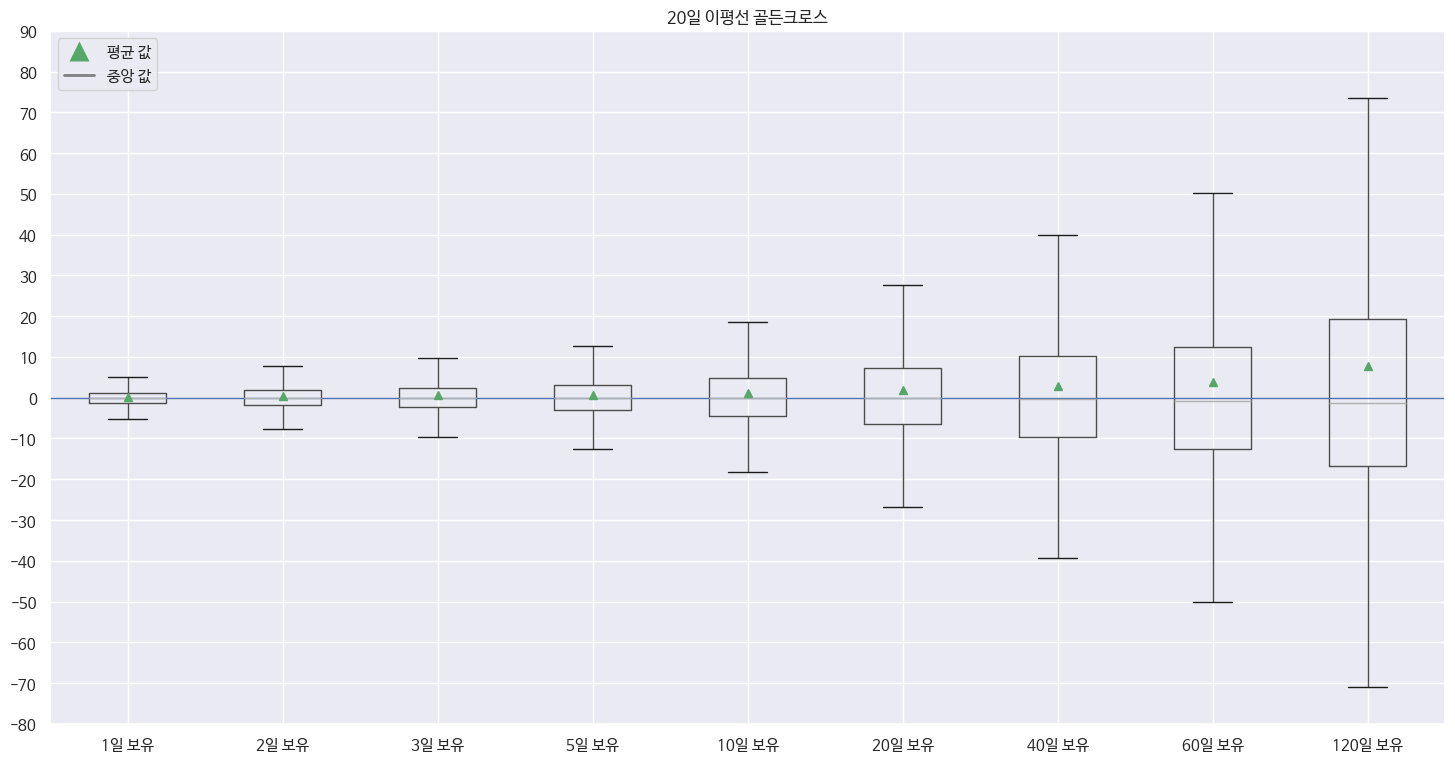

In [113]:
draw_meanmed_boxplot(exp['ret_goldencross_sma20d'], '20일 이평선 골든크로스');

In [114]:
describe_and_aggperf(exp['ret_goldencross_sma120d'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"38,462.0000","38,407.0000","38,380.0000","38,300.0000","38,118.0000","37,687.0000","37,050.0000","36,316.0000","34,100.0000"
mean,0.0017,0.0026,0.0031,0.0034,0.0055,0.0111,0.0201,0.0300,0.0798
std,0.0398,0.0551,0.0659,0.0834,0.1202,0.1820,0.2616,0.3068,0.5009
min,-0.4983,-0.5019,-0.5080,-0.6004,-0.9494,-0.9832,-0.9832,-0.9853,-0.9853
25%,-0.0146,-0.0212,-0.0262,-0.0341,-0.0491,-0.0719,-0.1055,-0.1295,-0.1774
50%,0.0000,-0.0015,-0.0016,-0.0028,-0.0039,-0.0067,-0.0125,-0.0176,-0.0184
75%,0.0126,0.0191,0.0236,0.0293,0.0419,0.0629,0.0889,0.1149,0.1973
max,0.3001,0.6892,1.1948,2.0591,3.1270,9.4788,13.2143,7.8000,18.4797
win_rate,0.5087,0.4933,0.4936,0.4810,0.4786,0.4702,0.4599,0.4567,0.4698
win_count,"19,566.0000","18,948.0000","18,946.0000","18,423.0000","18,242.0000","17,720.0000","17,039.0000","16,586.0000","16,019.0000"


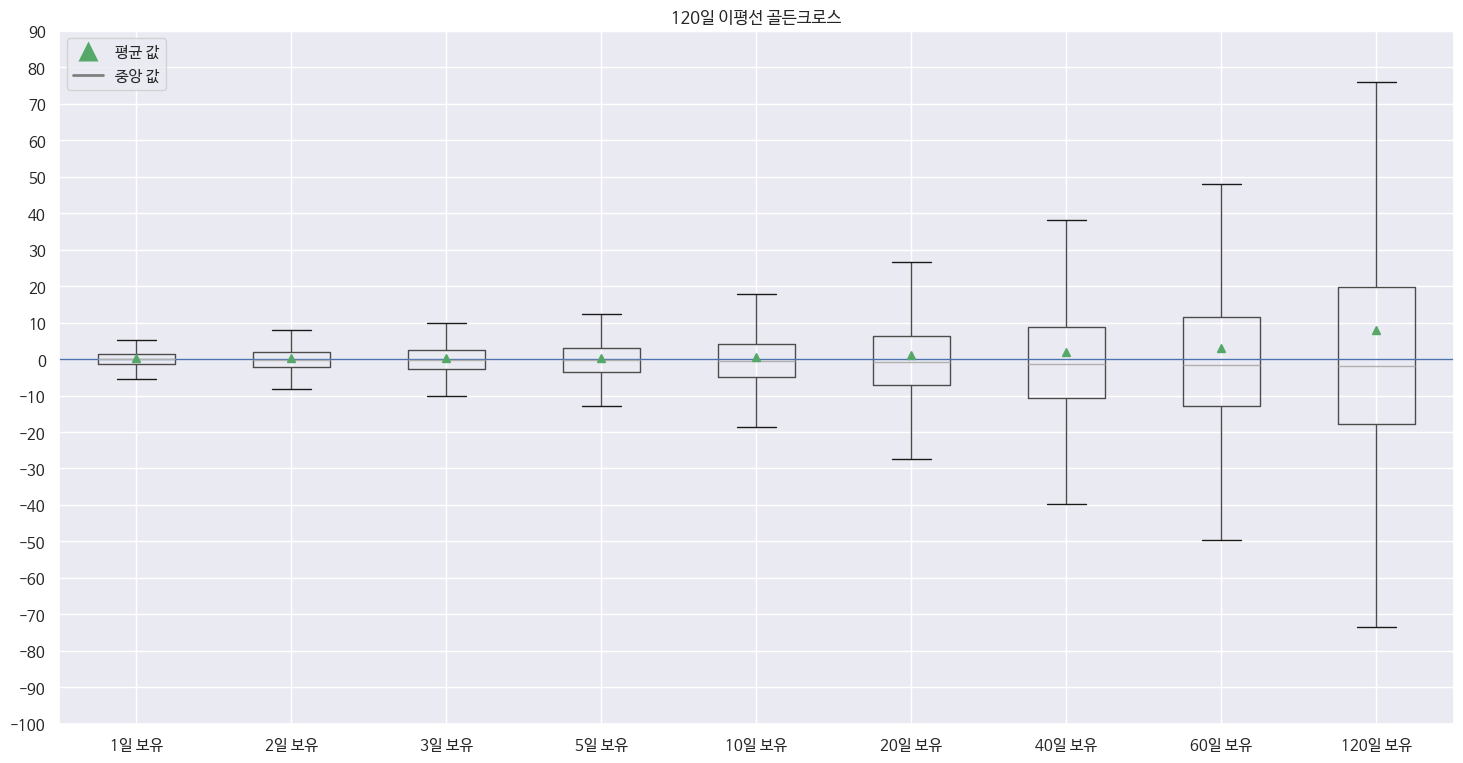

In [115]:
draw_meanmed_boxplot(exp['ret_goldencross_sma120d'], '120일 이평선 골든크로스');

## 볼린저밴드를 이용한 투자전략1: 볼린저밴드의 폭 너비에 따라 매수할 때

볼린저밴드 상한선:  20일 이평선 + 2 std       
볼린저밴드 하한선:  20일 이평선 - 2 std  
볼린저밴드의 폭:  4 std

In [116]:
d['bbw_20d_4std'] = d['adj_close'].rolling(20, axis=1, min_periods=10).std() * 4
d['bbw_20d_4std__adj_close'] = d['bbw_20d_4std'] / d['adj_close']

/tmp/ipykernel_598/1263654952.py:1: FutureWarning: Support for axis=1 in DataFrame.rolling is deprecated and will be removed in a future version. Use obj.T.rolling(...) instead
  d['bbw_20d_4std'] = d['adj_close'].rolling(20, axis=1, min_periods=10).std() * 4


/tmp/ipykernel_598/3152549270.py:1: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  sns.boxplot(y=d['bbw_20d_4std__adj_close'].stack(dropna=False), showfliers=False);


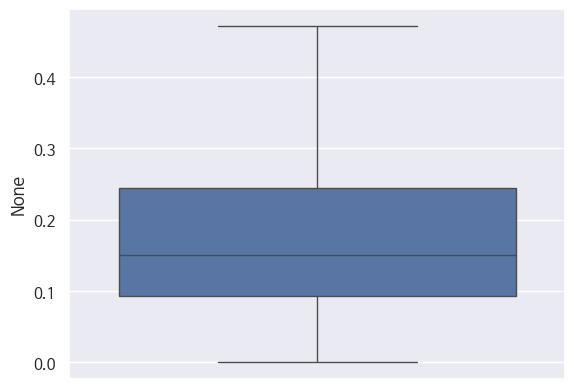

In [117]:
sns.boxplot(y=d['bbw_20d_4std__adj_close'].stack(dropna=False), showfliers=False);

In [118]:
d['bbw_20d_4std__adj_close'].stack().describe()

,0
count,"1,931,949.0000"
mean,0.2148
std,1.3776
min,0.0000
25%,0.0928
50%,0.1504
75%,0.2443
max,299.3453


In [119]:
wide_bbw_midxs = master_midxs[d['bbw_20d_4std__adj_close'].stack(dropna=False) > 0.25]
narrow_bbw_midxs = master_midxs[d['bbw_20d_4std__adj_close'].stack(dropna=False) < 0.10]
others_bbw_midxs = set(master_midxs) - set(wide_bbw_midxs) - set(narrow_bbw_midxs)

/tmp/ipykernel_598/385046001.py:1: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  wide_bbw_midxs = master_midxs[d['bbw_20d_4std__adj_close'].stack(dropna=False) > 0.25]
/tmp/ipykernel_598/385046001.py:2: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  narrow_bbw_midxs = master_midxs[d['bbw_20d_4std__adj_close'].stack(dropna=False) < 0.10]


In [121]:
for ret_nm, _midxs in zip(['ret_wide_bbw', 'ret_narrow_bbw', 'ret_others_bbw'], [wide_bbw_midxs, narrow_bbw_midxs, others_bbw_midxs]):
    # _midxs가 set(집합) 타입일 경우 list로 변환하여 전달합니다.
    safe_midxs = list(_midxs) if isinstance(_midxs, set) else _midxs
    exp[ret_nm] = get_all_return_df_by(d, safe_midxs)

/tmp/ipykernel_598/1174398668.py:4: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  return pd.concat([pd.Series(d[f'close_return_{hold_day}d'].stack(dropna=False).loc[midxs], name=f'{hold_day}일 보유') for hold_day in hold_day_li], axis=1)
/tmp/ipykernel_598/1174398668.py:4: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  return pd.concat([pd.Series(d[f'close_return_{hold_day}d'].stack(dropna=False).loc[midxs], name=f'{hold_day}일 보유') for hold_day in hold_day_li], axis=1)
/tmp/ipykernel_598/1174398668.py:4: FutureWarning: The previous implementation of stack is deprecated and 

In [122]:
describe_and_aggperf(exp['ret_wide_bbw'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"463,479.0000","463,122.0000","462,770.0000","462,054.0000","460,227.0000","456,865.0000","450,139.0000","441,072.0000","410,922.0000"
mean,0.0013,0.0028,0.0044,0.0078,0.0170,0.0373,0.0608,0.0810,0.1354
std,0.0511,0.0733,0.0911,0.1191,0.1670,0.2293,0.3280,0.3982,0.6140
min,-0.9000,-0.9146,-0.9456,-0.9639,-0.9648,-0.9730,-0.9731,-0.9731,-0.9897
25%,-0.0226,-0.0324,-0.0403,-0.0512,-0.0692,-0.0903,-0.1198,-0.1383,-0.1941
50%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0049,0.0027,0.0103,0.0094
75%,0.0213,0.0323,0.0411,0.0541,0.0782,0.1200,0.1657,0.2030,0.2906
max,1.1009,1.1916,1.1962,3.3450,3.7999,5.0040,13.6324,18.1382,20.3313
win_rate,0.5213,0.5077,0.5068,0.5076,0.5105,0.5226,0.5132,0.5244,0.5168
win_count,"241,592.0000","235,121.0000","234,536.0000","234,546.0000","234,938.0000","238,765.0000","231,033.0000","231,306.0000","212,378.0000"


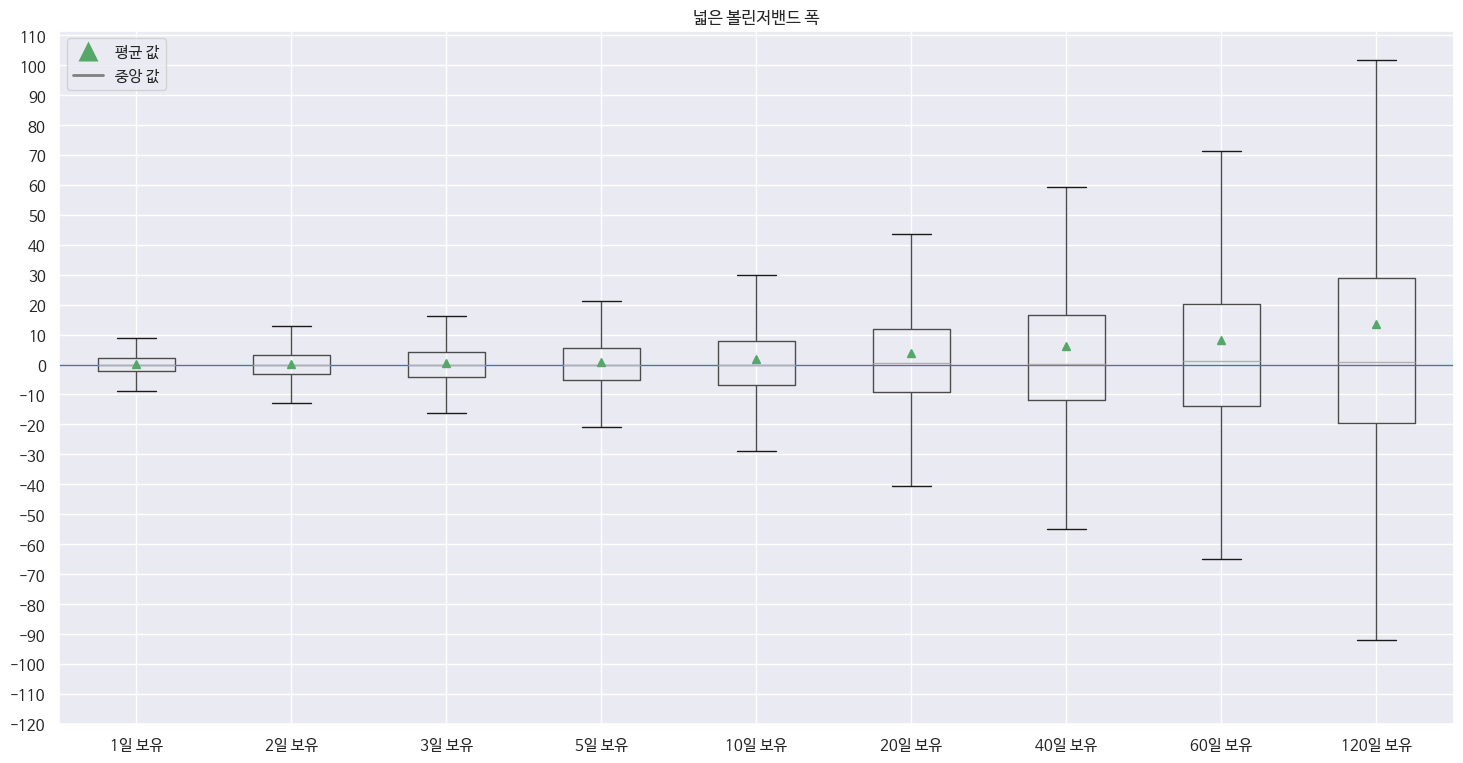

In [123]:
draw_meanmed_boxplot(exp['ret_wide_bbw'], '넓은 볼린저밴드 폭');

In [124]:
describe_and_aggperf(exp['ret_narrow_bbw'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"544,095.0000","543,203.0000","542,323.0000","540,556.0000","535,954.0000","525,713.0000","506,444.0000","493,041.0000","451,659.0000"
mean,0.0006,0.0012,0.0017,0.0027,0.0044,0.0054,0.0118,0.0136,0.0350
std,0.0211,0.0314,0.0396,0.0528,0.0779,0.1203,0.1849,0.2335,0.3658
min,-0.9732,-0.9753,-0.9829,-0.9932,-0.9932,-0.9932,-0.9932,-0.9932,-0.9932
25%,-0.0056,-0.0086,-0.0108,-0.0143,-0.0218,-0.0346,-0.0531,-0.0775,-0.1207
50%,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
75%,0.0049,0.0080,0.0101,0.0141,0.0213,0.0308,0.0484,0.0587,0.0875
max,1.9080,1.9080,2.0272,2.7019,3.1326,4.7057,5.3238,7.5497,15.3614
win_rate,0.6286,0.6119,0.6082,0.6041,0.5975,0.5867,0.5827,0.5637,0.5370
win_count,"342,030.0000","332,391.0000","329,848.0000","326,563.0000","320,232.0000","308,447.0000","295,124.0000","277,914.0000","242,560.0000"


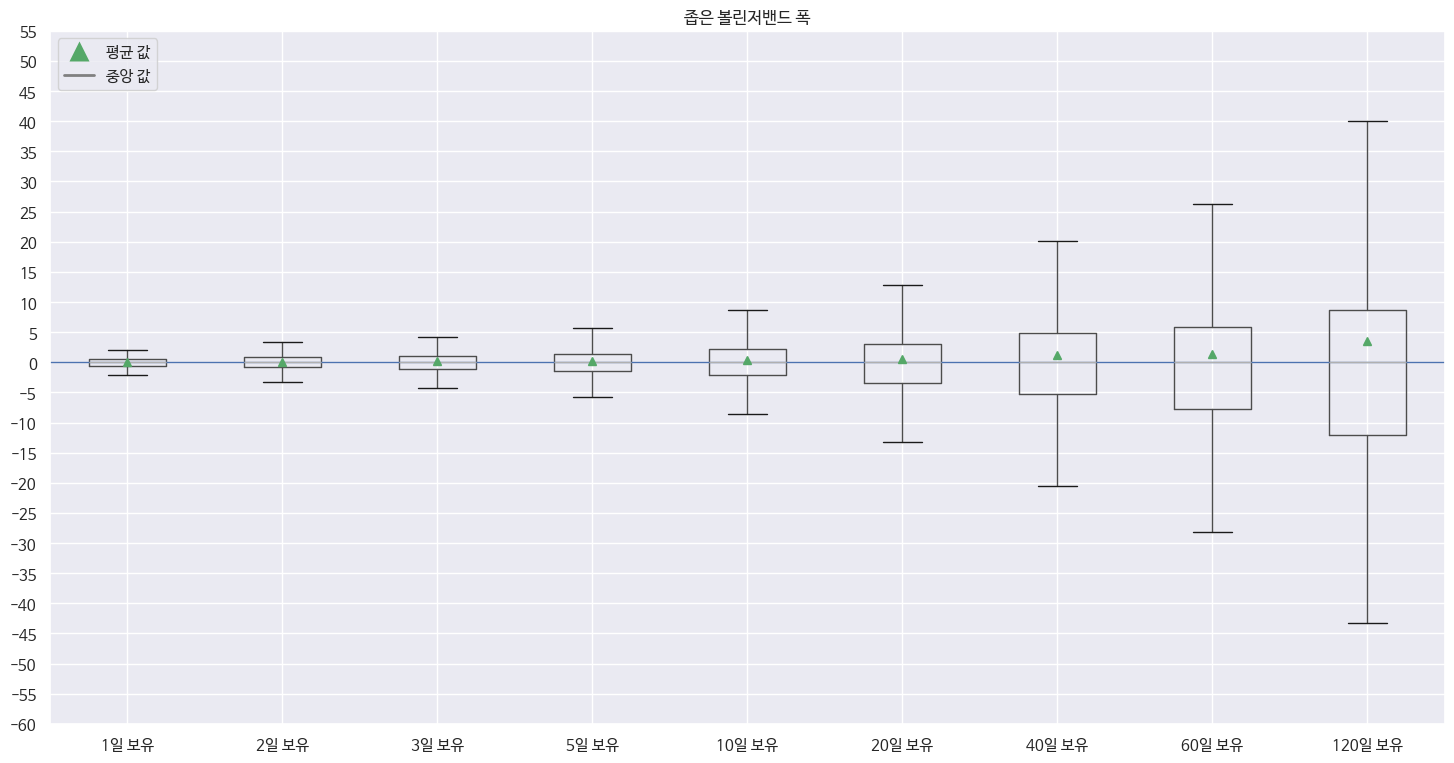

In [125]:
draw_meanmed_boxplot(exp['ret_narrow_bbw'], '좁은 볼린저밴드 폭');

In [126]:
describe_and_aggperf(exp['ret_others_bbw'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"943,536.0000","942,389.0000","941,225.0000","938,917.0000","933,374.0000","923,057.0000","901,272.0000","876,151.0000","805,933.0000"
mean,0.0006,0.0011,0.0018,0.0030,0.0059,0.0112,0.0254,0.0402,0.0685
std,0.0321,0.0470,0.0588,0.0777,0.1131,0.1703,0.2492,0.3167,0.4577
min,-0.5179,-0.6250,-0.7162,-0.8079,-0.9468,-0.9600,-0.9669,-0.9669,-0.9897
25%,-0.0148,-0.0218,-0.0271,-0.0354,-0.0511,-0.0732,-0.1014,-0.1256,-0.1780
50%,0.0000,-0.0015,-0.0019,-0.0026,-0.0034,-0.0044,-0.0061,-0.0088,-0.0230
75%,0.0126,0.0193,0.0243,0.0321,0.0476,0.0709,0.1040,0.1339,0.1941
max,0.8650,0.8650,1.1955,2.7073,3.4898,12.2667,9.7584,20.8197,18.4797
win_rate,0.5081,0.4935,0.4909,0.4878,0.4876,0.4865,0.4857,0.4829,0.4673
win_count,"479,456.0000","465,079.0000","462,039.0000","458,046.0000","455,077.0000","449,037.0000","437,754.0000","423,124.0000","376,640.0000"


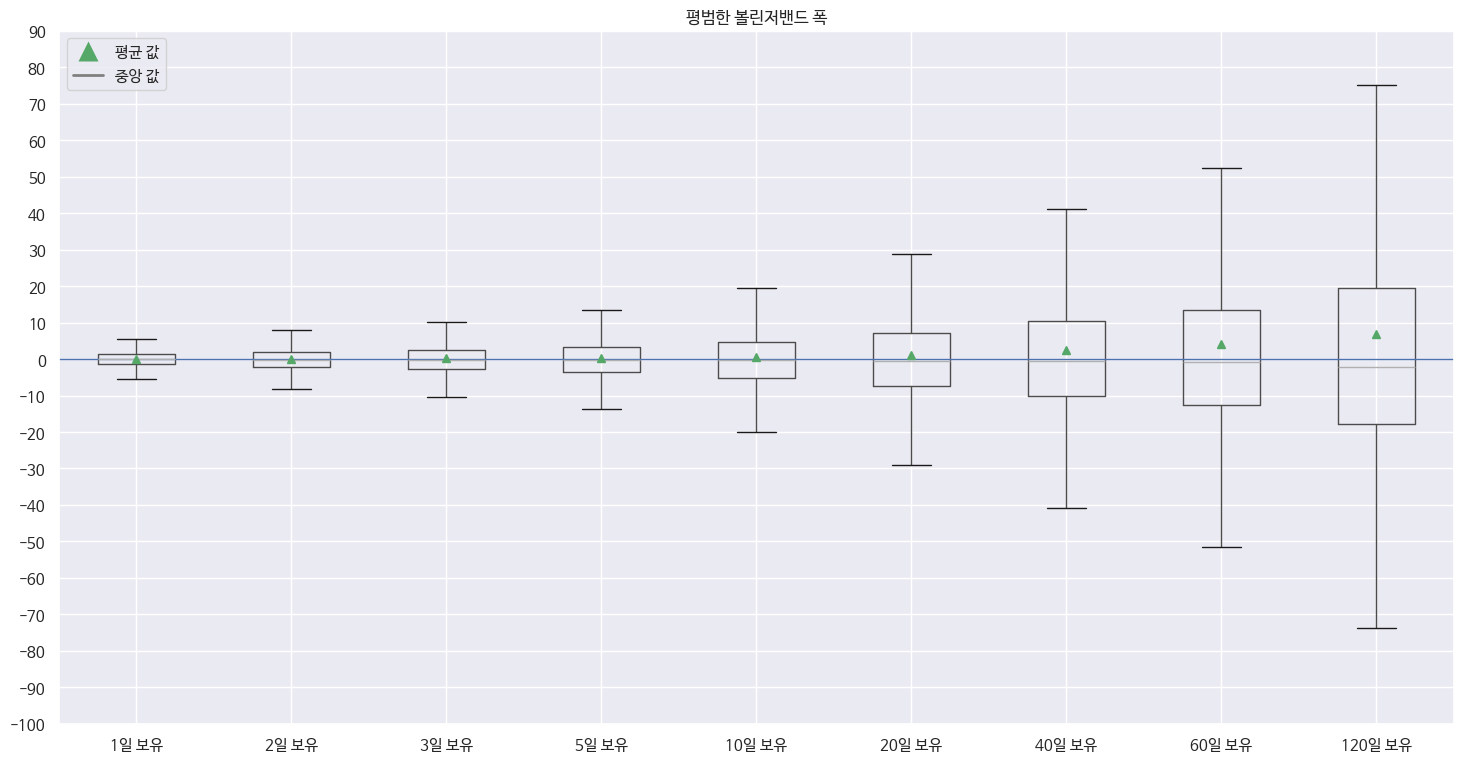

In [127]:
draw_meanmed_boxplot(exp['ret_others_bbw'], '평범한 볼린저밴드 폭');

## 볼린저밴드를 이용한 투자전략2: 상한선 위에서 매수할 때, 하한선 아래에서 매수할 때

In [128]:
exp.keys()

dict_keys(['ret_lt_sma5d', 'ret_gt_sma5d', 'ret_lt_sma10d', 'ret_gt_sma10d', 'ret_lt_sma20d', 'ret_gt_sma20d', 'ret_lt_sma40d', 'ret_gt_sma40d', 'ret_lt_sma60d', 'ret_gt_sma60d', 'ret_lt_sma120d', 'ret_gt_sma120d', 'ret_sma_aligned', 'ret_sma_inverse_aligned', 'ret_sma_not_aligned', 'ret_goldencross_sma5d', 'ret_goldencross_sma10d', 'ret_goldencross_sma20d', 'ret_goldencross_sma40d', 'ret_goldencross_sma60d', 'ret_goldencross_sma120d', 'ret_wide_bbw', 'ret_narrow_bbw', 'ret_others_bbw'])

In [129]:
d['bbh_20d_2std'] = d['adj_close_sma20d'] + 2*d['adj_close'].rolling(20, axis=1).std()
d['bbl_20d_2std'] = d['adj_close_sma20d'] - 2*d['adj_close'].rolling(20, axis=1).std()

/tmp/ipykernel_598/784776458.py:1: FutureWarning: Support for axis=1 in DataFrame.rolling is deprecated and will be removed in a future version. Use obj.T.rolling(...) instead
  d['bbh_20d_2std'] = d['adj_close_sma20d'] + 2*d['adj_close'].rolling(20, axis=1).std()
/tmp/ipykernel_598/784776458.py:2: FutureWarning: Support for axis=1 in DataFrame.rolling is deprecated and will be removed in a future version. Use obj.T.rolling(...) instead
  d['bbl_20d_2std'] = d['adj_close_sma20d'] - 2*d['adj_close'].rolling(20, axis=1).std()


In [130]:
over_narrow_bbh_midxs = master_midxs[((d['bbw_20d_4std__adj_close'] < 0.1) & (d['adj_close'] > d['bbh_20d_2std'])).stack(dropna=False)]
under_narrow_bbl_midxs = master_midxs[((d['bbw_20d_4std__adj_close'] < 0.1) & (d['adj_close'] < d['bbl_20d_2std'])).stack(dropna=False)]

over_wide_bbh_midxs = master_midxs[((d['bbw_20d_4std__adj_close'] > 0.25) & (d['adj_close'] > d['bbh_20d_2std'])).stack(dropna=False)]
under_wide_bbl_midxs = master_midxs[((d['bbw_20d_4std__adj_close'] > 0.25) & (d['adj_close'] < d['bbl_20d_2std'])).stack(dropna=False)]

/tmp/ipykernel_598/864804482.py:1: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  over_narrow_bbh_midxs = master_midxs[((d['bbw_20d_4std__adj_close'] < 0.1) & (d['adj_close'] > d['bbh_20d_2std'])).stack(dropna=False)]
/tmp/ipykernel_598/864804482.py:2: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  under_narrow_bbl_midxs = master_midxs[((d['bbw_20d_4std__adj_close'] < 0.1) & (d['adj_close'] < d['bbl_20d_2std'])).stack(dropna=False)]
/tmp/ipykernel_598/864804482.py:4: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version 

In [131]:
exp['ret_over_narrow_bbh'] = get_all_return_df_by(d, over_narrow_bbh_midxs)
exp['ret_under_narrow_bbl'] = get_all_return_df_by(d, under_narrow_bbl_midxs)

exp['ret_over_wide_bbh'] = get_all_return_df_by(d, over_wide_bbh_midxs)
exp['ret_under_wide_bbl'] = get_all_return_df_by(d, under_wide_bbl_midxs)

/tmp/ipykernel_598/1174398668.py:4: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  return pd.concat([pd.Series(d[f'close_return_{hold_day}d'].stack(dropna=False).loc[midxs], name=f'{hold_day}일 보유') for hold_day in hold_day_li], axis=1)
/tmp/ipykernel_598/1174398668.py:4: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  return pd.concat([pd.Series(d[f'close_return_{hold_day}d'].stack(dropna=False).loc[midxs], name=f'{hold_day}일 보유') for hold_day in hold_day_li], axis=1)
/tmp/ipykernel_598/1174398668.py:4: FutureWarning: The previous implementation of stack is deprecated and 

In [132]:
describe_and_aggperf(exp['ret_over_narrow_bbh'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"26,374.0000","26,355.0000","26,340.0000","26,305.0000","26,183.0000","25,689.0000","24,733.0000","23,927.0000","21,271.0000"
mean,0.0020,0.0029,0.0033,0.0037,0.0076,0.0128,0.0256,0.0289,0.0655
std,0.0288,0.0410,0.0490,0.0616,0.0889,0.1321,0.2027,0.2522,0.3980
min,-0.2531,-0.2683,-0.3031,-0.3580,-0.6120,-0.5899,-0.6549,-0.8079,-0.9397
25%,-0.0104,-0.0154,-0.0192,-0.0242,-0.0343,-0.0494,-0.0687,-0.0935,-0.1418
50%,0.0000,-0.0015,-0.0021,-0.0025,-0.0024,-0.0031,0.0000,-0.0019,-0.0122
75%,0.0086,0.0134,0.0166,0.0206,0.0321,0.0497,0.0788,0.0975,0.1616
max,0.3000,0.6893,1.1885,2.6899,2.7395,3.3035,4.7945,4.8937,11.4312
win_rate,0.5119,0.4919,0.4860,0.4761,0.4852,0.4845,0.5066,0.4982,0.4719
win_count,"13,501.0000","12,964.0000","12,801.0000","12,524.0000","12,705.0000","12,447.0000","12,529.0000","11,920.0000","10,038.0000"


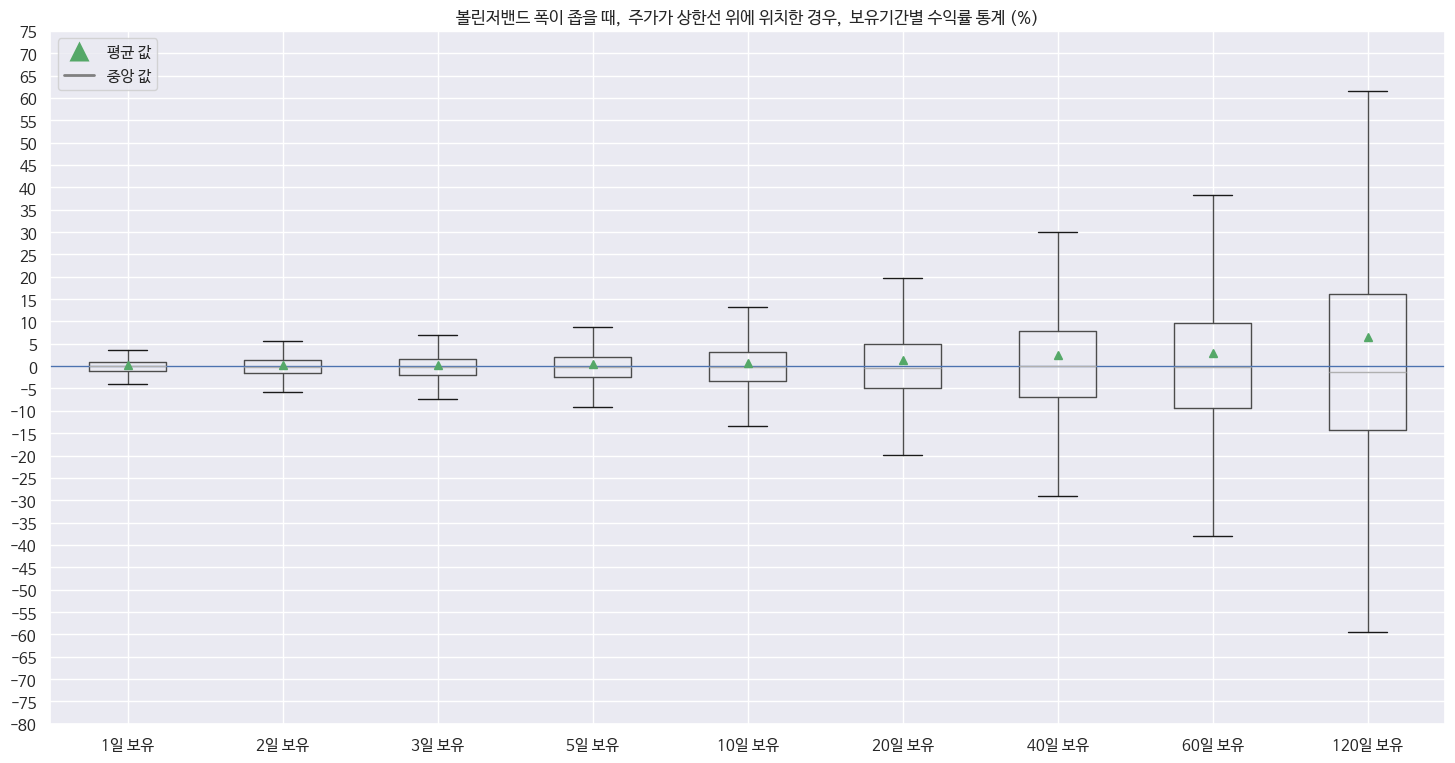

In [133]:
draw_meanmed_boxplot(exp['ret_over_narrow_bbh'], _title='볼린저밴드 폭이 좁을 때,  주가가 상한선 위에 위치한 경우,  보유기간별 수익률 통계 (%)');

In [134]:
describe_and_aggperf(exp['ret_under_narrow_bbl'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"19,531.0000","19,519.0000","19,483.0000","19,440.0000","19,270.0000","18,673.0000","18,303.0000","18,109.0000","17,280.0000"
mean,-0.0010,-0.0009,-0.0000,0.0011,-0.0019,-0.0088,0.0038,0.0079,0.0432
std,0.0217,0.0312,0.0389,0.0500,0.0744,0.1261,0.1753,0.2356,0.3738
min,-0.2991,-0.3323,-0.3133,-0.4079,-0.4483,-0.6045,-0.6871,-0.7926,-0.7926
25%,-0.0101,-0.0151,-0.0170,-0.0204,-0.0362,-0.0603,-0.0793,-0.1070,-0.1373
50%,0.0000,0.0000,0.0013,0.0016,-0.0014,-0.0071,-0.0072,-0.0177,-0.0232
75%,0.0094,0.0135,0.0170,0.0218,0.0270,0.0358,0.0598,0.0677,0.1183
max,0.3000,0.6872,0.7192,0.8721,1.8889,2.9946,3.3566,3.9369,8.2908
win_rate,0.5594,0.5359,0.5451,0.5421,0.4964,0.4630,0.4712,0.4457,0.4462
win_count,"10,926.0000","10,461.0000","10,620.0000","10,539.0000","9,566.0000","8,645.0000","8,624.0000","8,072.0000","7,711.0000"


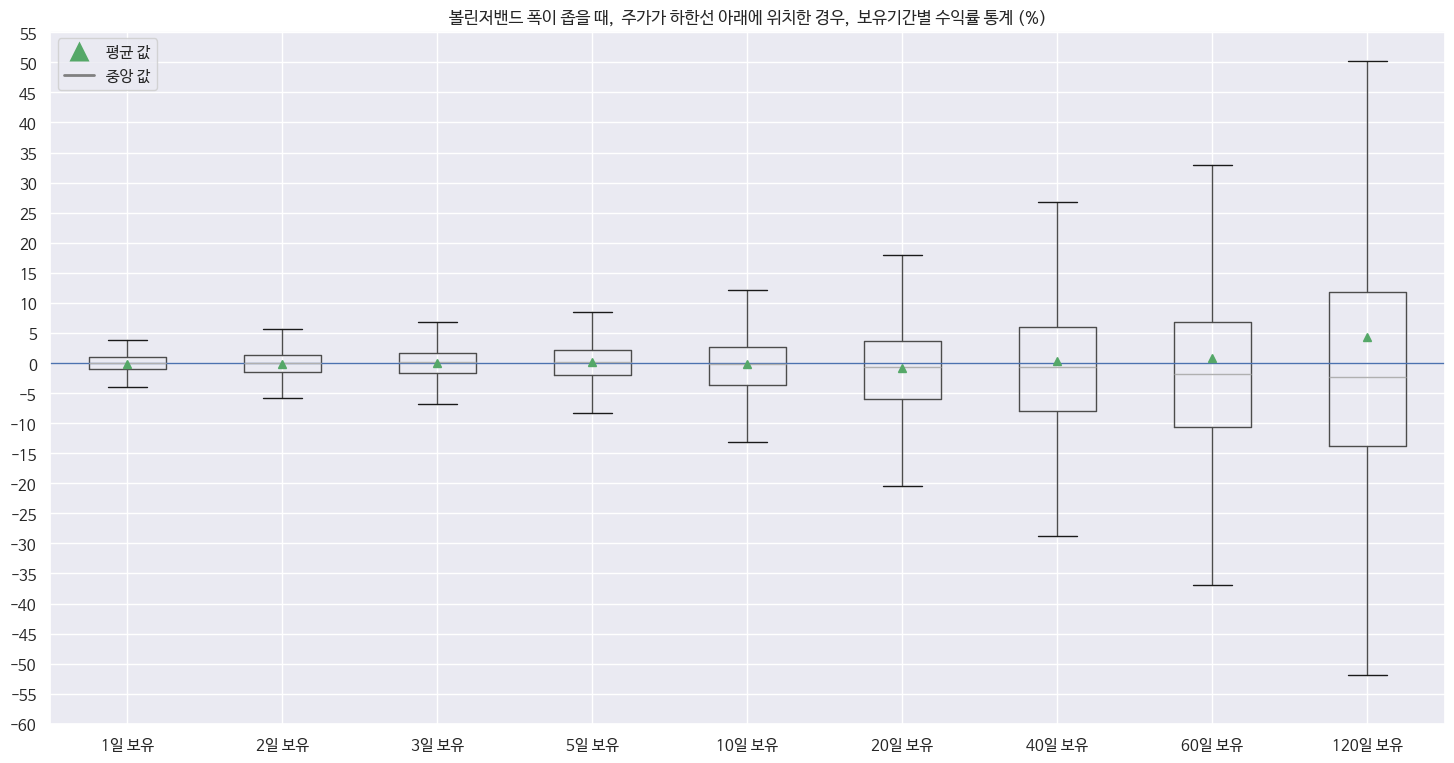

In [135]:
draw_meanmed_boxplot(exp['ret_under_narrow_bbl'], _title='볼린저밴드 폭이 좁을 때,  주가가 하한선 아래에 위치한 경우,  보유기간별 수익률 통계 (%)');

In [136]:
describe_and_aggperf(exp['ret_over_wide_bbh'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"25,385.0000","25,366.0000","25,356.0000","25,328.0000","25,203.0000","24,881.0000","24,294.0000","23,696.0000","21,323.0000"
mean,0.0021,0.0012,0.0002,-0.0005,0.0039,0.0136,0.0173,0.0297,0.0686
std,0.0767,0.1066,0.1285,0.1594,0.2069,0.2846,0.3698,0.4304,0.6607
min,-0.4983,-0.5019,-0.5599,-0.6413,-0.6821,-0.9698,-0.9731,-0.9731,-0.9731
25%,-0.0368,-0.0554,-0.0690,-0.0853,-0.1100,-0.1478,-0.1930,-0.2173,-0.2827
50%,-0.0027,-0.0099,-0.0158,-0.0236,-0.0287,-0.0443,-0.0567,-0.0639,-0.0798
75%,0.0268,0.0394,0.0449,0.0539,0.0755,0.1049,0.1279,0.1551,0.2212
max,0.6872,1.1916,1.1946,2.1835,3.3450,5.0040,5.6718,8.3089,15.0250
win_rate,0.4861,0.4481,0.4303,0.4126,0.4167,0.4089,0.4032,0.4083,0.4161
win_count,"12,339.0000","11,366.0000","10,911.0000","10,450.0000","10,501.0000","10,175.0000","9,795.0000","9,674.0000","8,873.0000"


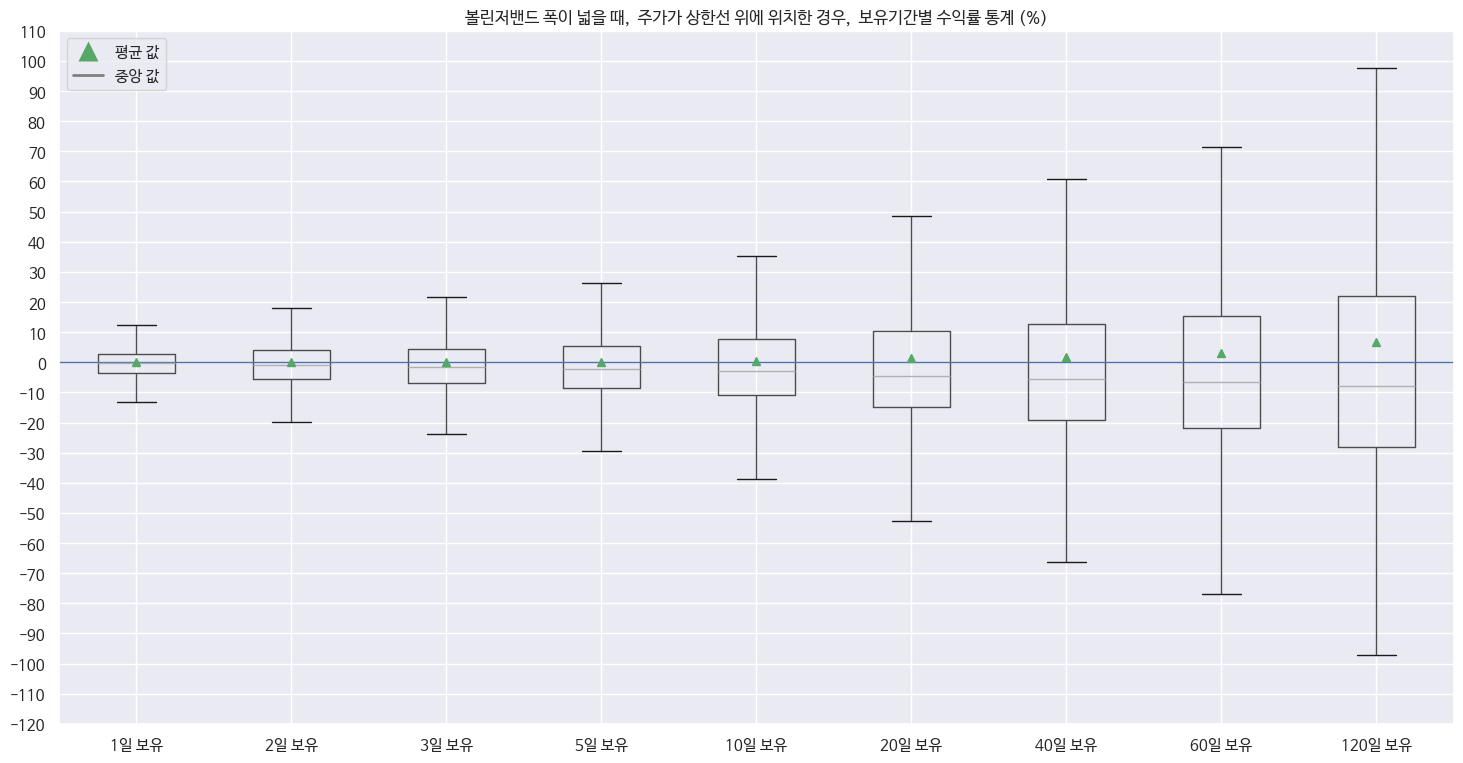

In [137]:
draw_meanmed_boxplot(exp['ret_over_wide_bbh'], _title='볼린저밴드 폭이 넓을 때,  주가가 상한선 위에 위치한 경우,  보유기간별 수익률 통계 (%)');

In [138]:
describe_and_aggperf(exp['ret_under_wide_bbl'])

,1일 보유,2일 보유,3일 보유,5일 보유,10일 보유,20일 보유,40일 보유,60일 보유,120일 보유
count,"24,742.0000","24,734.0000","24,730.0000","24,717.0000","24,693.0000","24,620.0000","24,526.0000","24,320.0000","23,560.0000"
mean,-0.0046,-0.0095,-0.0093,-0.0002,0.0422,0.1099,0.1785,0.2188,0.3441
std,0.0742,0.0976,0.1273,0.1669,0.1941,0.2661,0.3754,0.4487,0.7473
min,-0.6569,-0.8082,-0.8700,-0.8932,-0.8932,-0.8932,-0.8932,-0.9478,-0.9478
25%,-0.0386,-0.0546,-0.0779,-0.0841,-0.0675,-0.0405,-0.0410,-0.0398,-0.0632
50%,0.0015,0.0000,0.0056,0.0115,0.0224,0.0766,0.1117,0.1465,0.1795
75%,0.0332,0.0429,0.0622,0.0871,0.1279,0.2156,0.3222,0.3878,0.5333
max,0.5865,0.7299,1.1944,2.0123,2.1481,4.3858,13.4622,8.2733,20.3313
win_rate,0.5363,0.5074,0.5305,0.5488,0.5726,0.6714,0.6860,0.7041,0.6879
win_count,"13,270.0000","12,550.0000","13,119.0000","13,565.0000","14,139.0000","16,531.0000","16,824.0000","17,124.0000","16,206.0000"


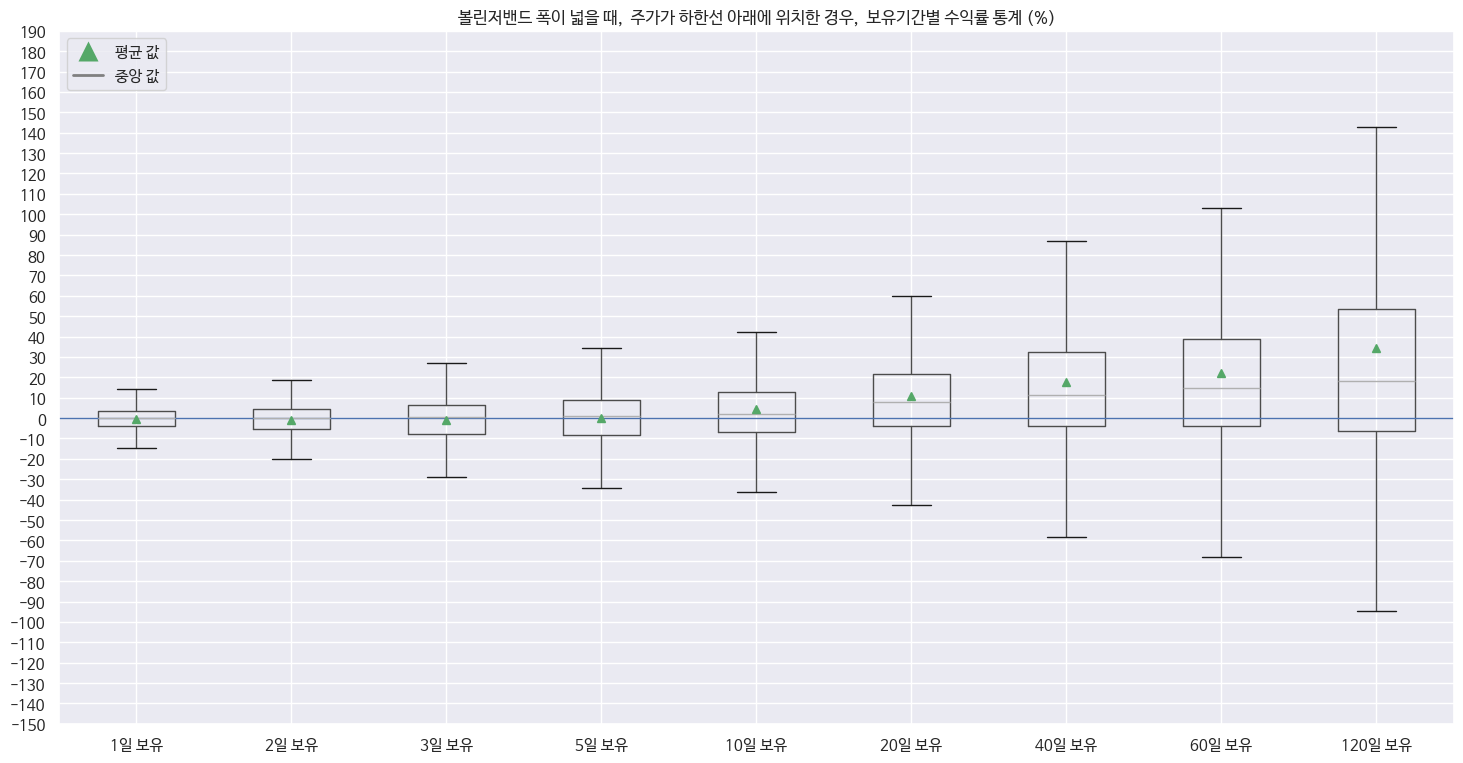

In [139]:
draw_meanmed_boxplot(exp['ret_under_wide_bbl'], _title='볼린저밴드 폭이 넓을 때,  주가가 하한선 아래에 위치한 경우,  보유기간별 수익률 통계 (%)');